В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import random

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
SEQUENCE_LENGTH = 365 * 4

# stocks

In [4]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,XRP,BNB,ADA,SOL,DOGE,DOT,LTC,LINK,...,XVG,BCN,NXT,PPC,NMC,DGB,SC,QTUM,ICX,LSK
Date,,,,,,,,,,,,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.058550,NaN,...,NaN,NaN,NaN,1.540270,1.264560,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.685230,NaN,...,NaN,NaN,NaN,1.685280,1.229760,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.327770,NaN,...,NaN,NaN,NaN,1.216330,1.104190,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.286440,NaN,...,NaN,NaN,NaN,1.641050,1.194410,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.245920,NaN,...,NaN,NaN,NaN,1.488790,1.110980,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,1.334452,740.823608,0.223782,106.422340,0.081809,1.149771,61.531612,12.320927,...,0.002583,0.000059,NaN,0.446449,1.317299,0.003360,0.000820,0.877745,0.009176,0.197685
2026-10-21,84011.968750,2470.766113,1.363619,745.868347,0.224979,106.793655,0.081867,1.141323,61.454342,12.484719,...,0.002605,0.000037,NaN,0.343409,1.176803,0.003399,0.000850,0.889200,0.008703,0.196787
2026-10-22,81311.890625,2386.189209,1.307656,730.476624,0.212025,103.542320,0.078676,1.111869,58.756485,11.943166,...,0.002455,0.000029,NaN,0.342047,1.535211,0.003527,0.000893,0.852186,0.009433,0.183983


In [5]:
strategy={}

17:42:08 - cmdstanpy - INFO - Chain [1] start processing
17:42:08 - cmdstanpy - INFO - Chain [1] done processing


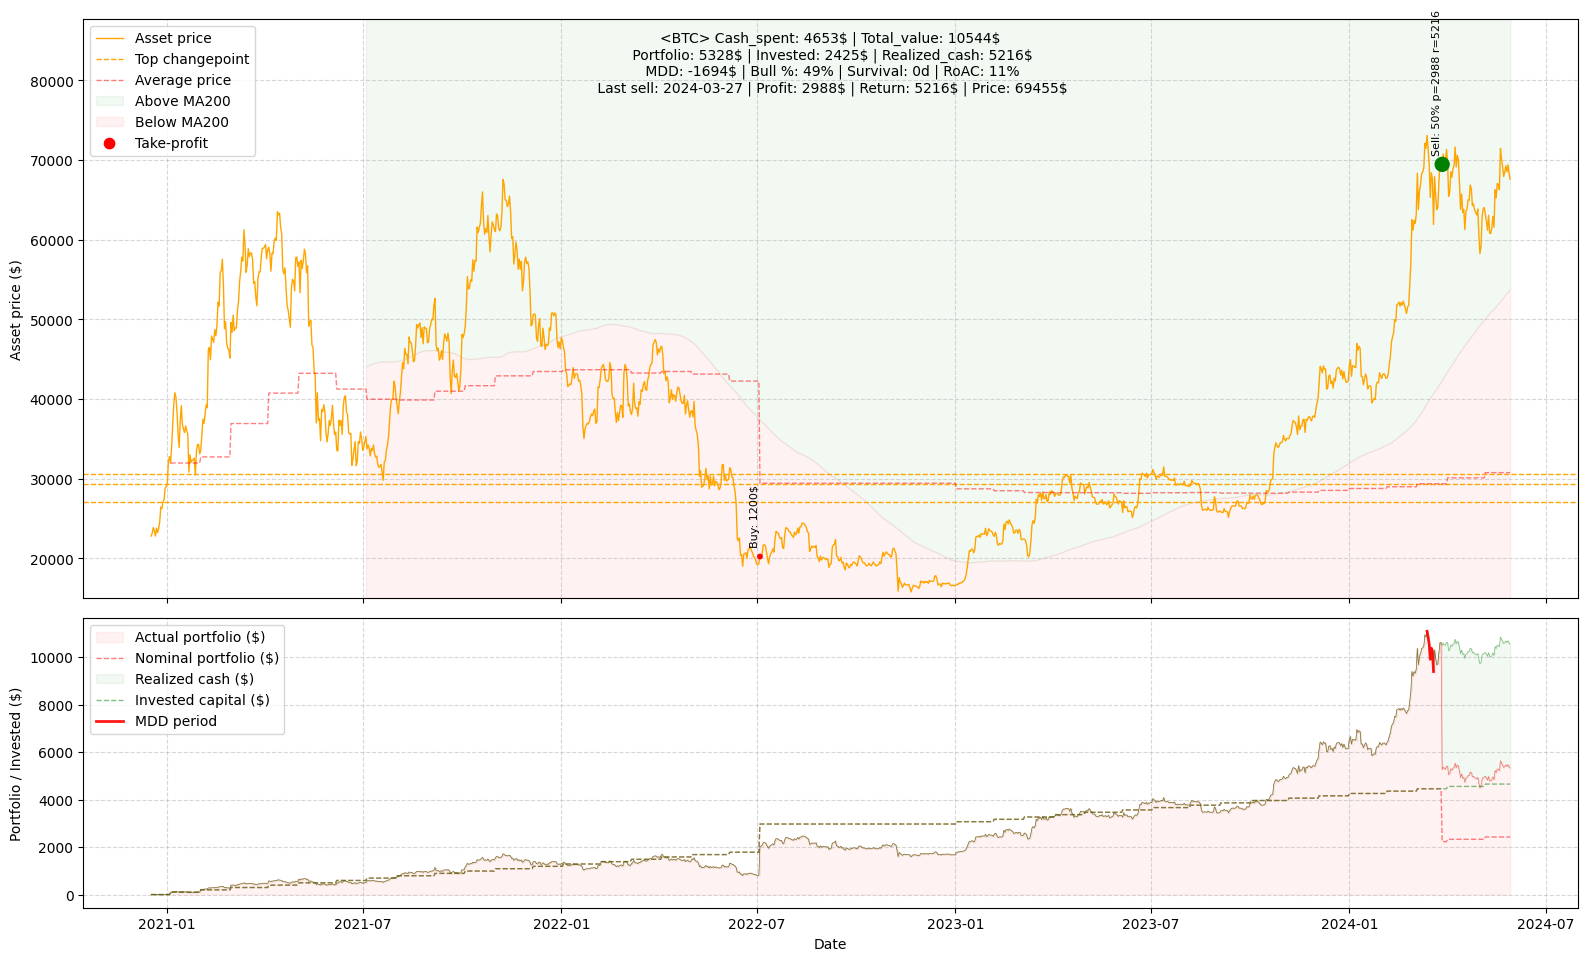

17:42:08 - cmdstanpy - INFO - Chain [1] start processing
17:42:09 - cmdstanpy - INFO - Chain [1] done processing


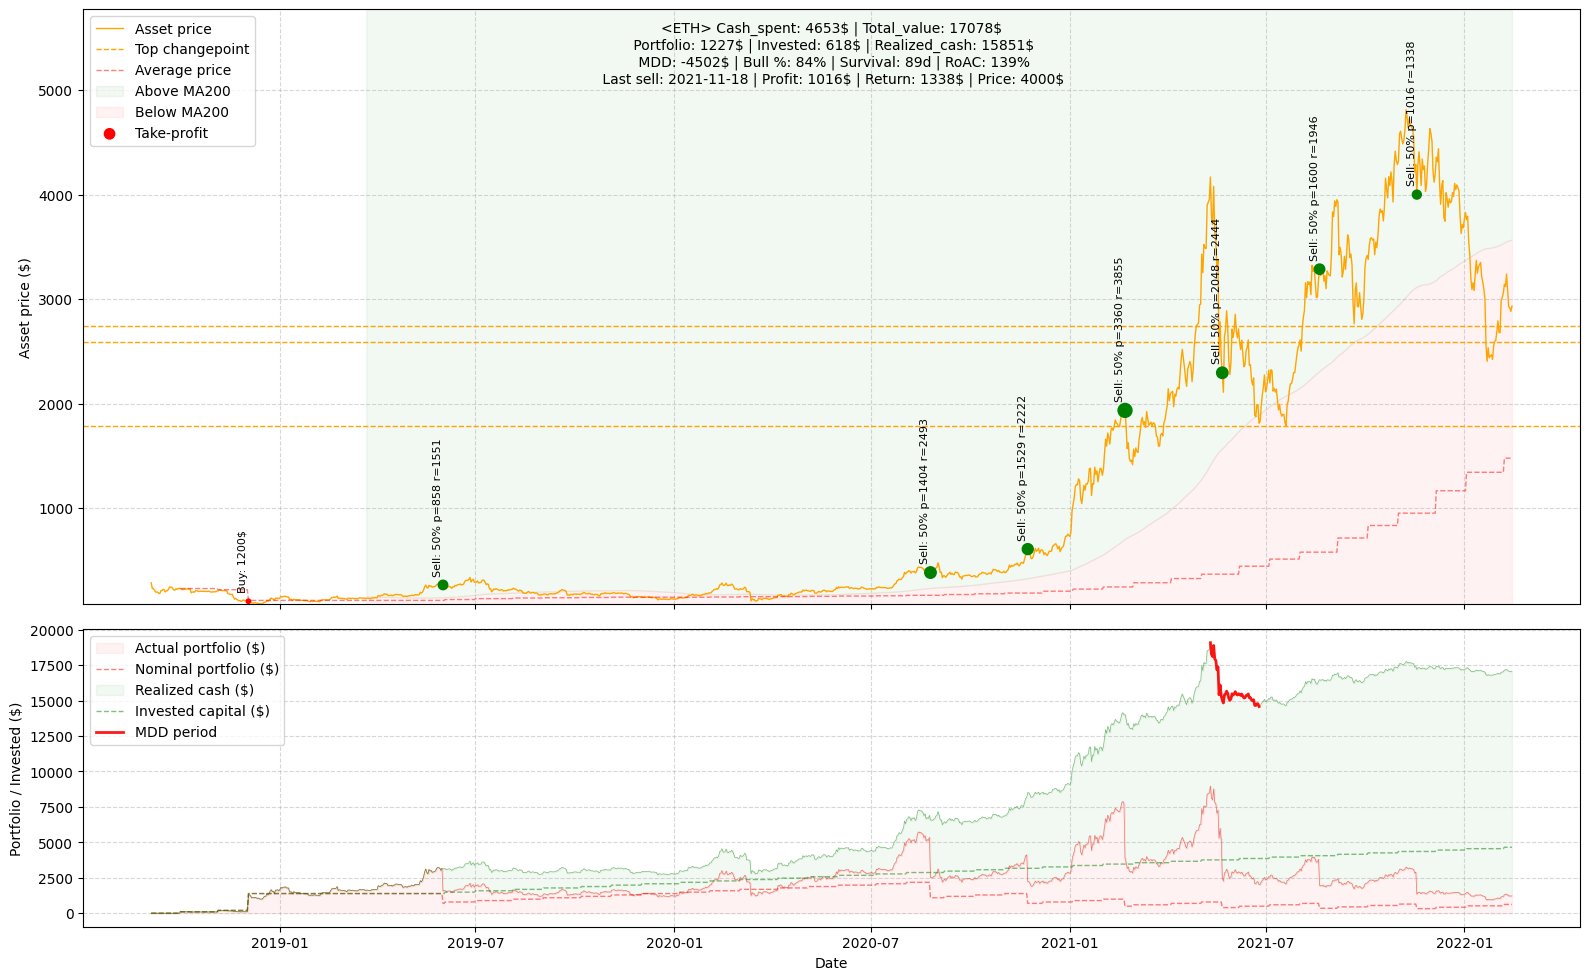

17:42:09 - cmdstanpy - INFO - Chain [1] start processing
17:42:09 - cmdstanpy - INFO - Chain [1] done processing


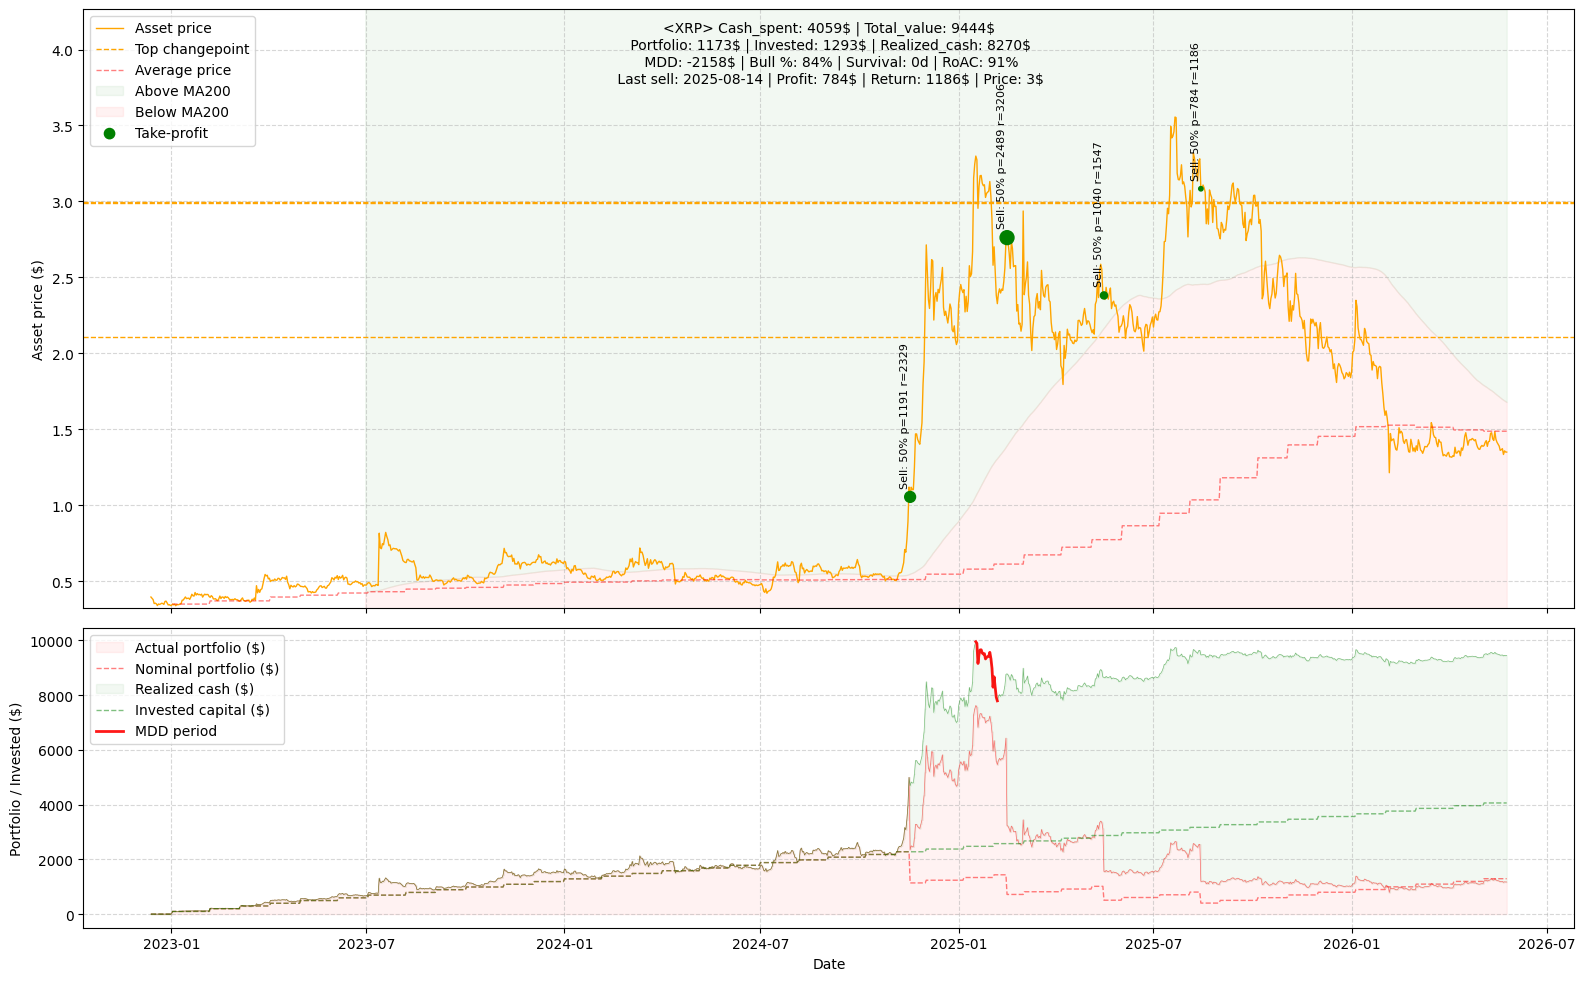

17:42:09 - cmdstanpy - INFO - Chain [1] start processing
17:42:10 - cmdstanpy - INFO - Chain [1] done processing


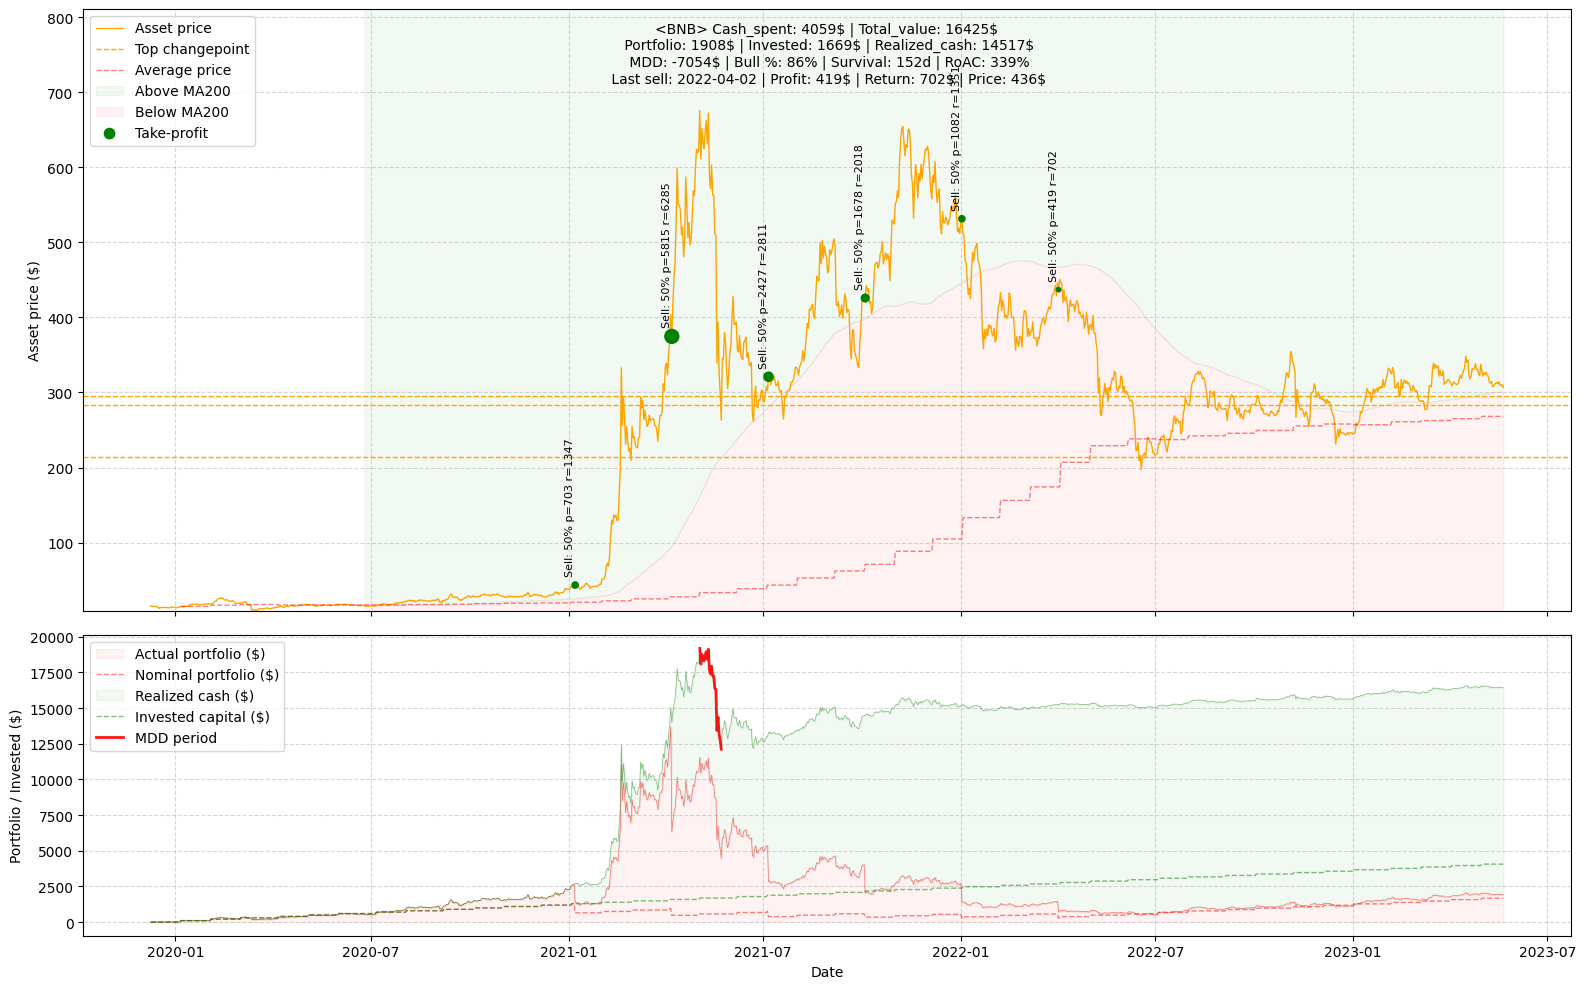

17:42:10 - cmdstanpy - INFO - Chain [1] start processing
17:42:10 - cmdstanpy - INFO - Chain [1] done processing


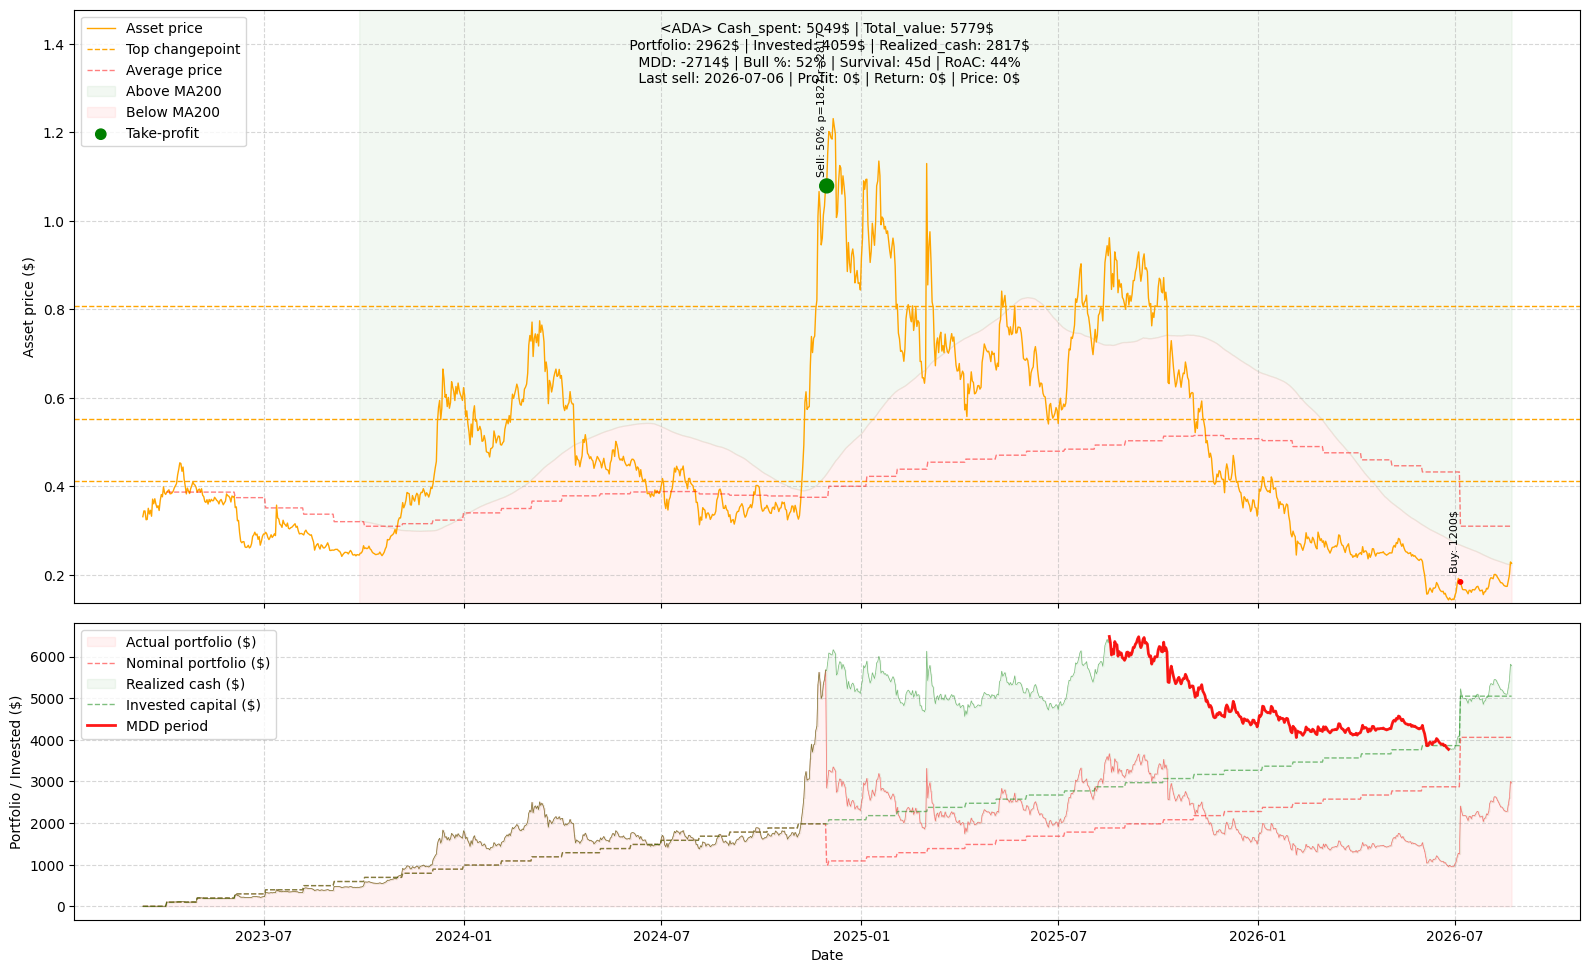

17:42:10 - cmdstanpy - INFO - Chain [1] start processing
17:42:11 - cmdstanpy - INFO - Chain [1] done processing


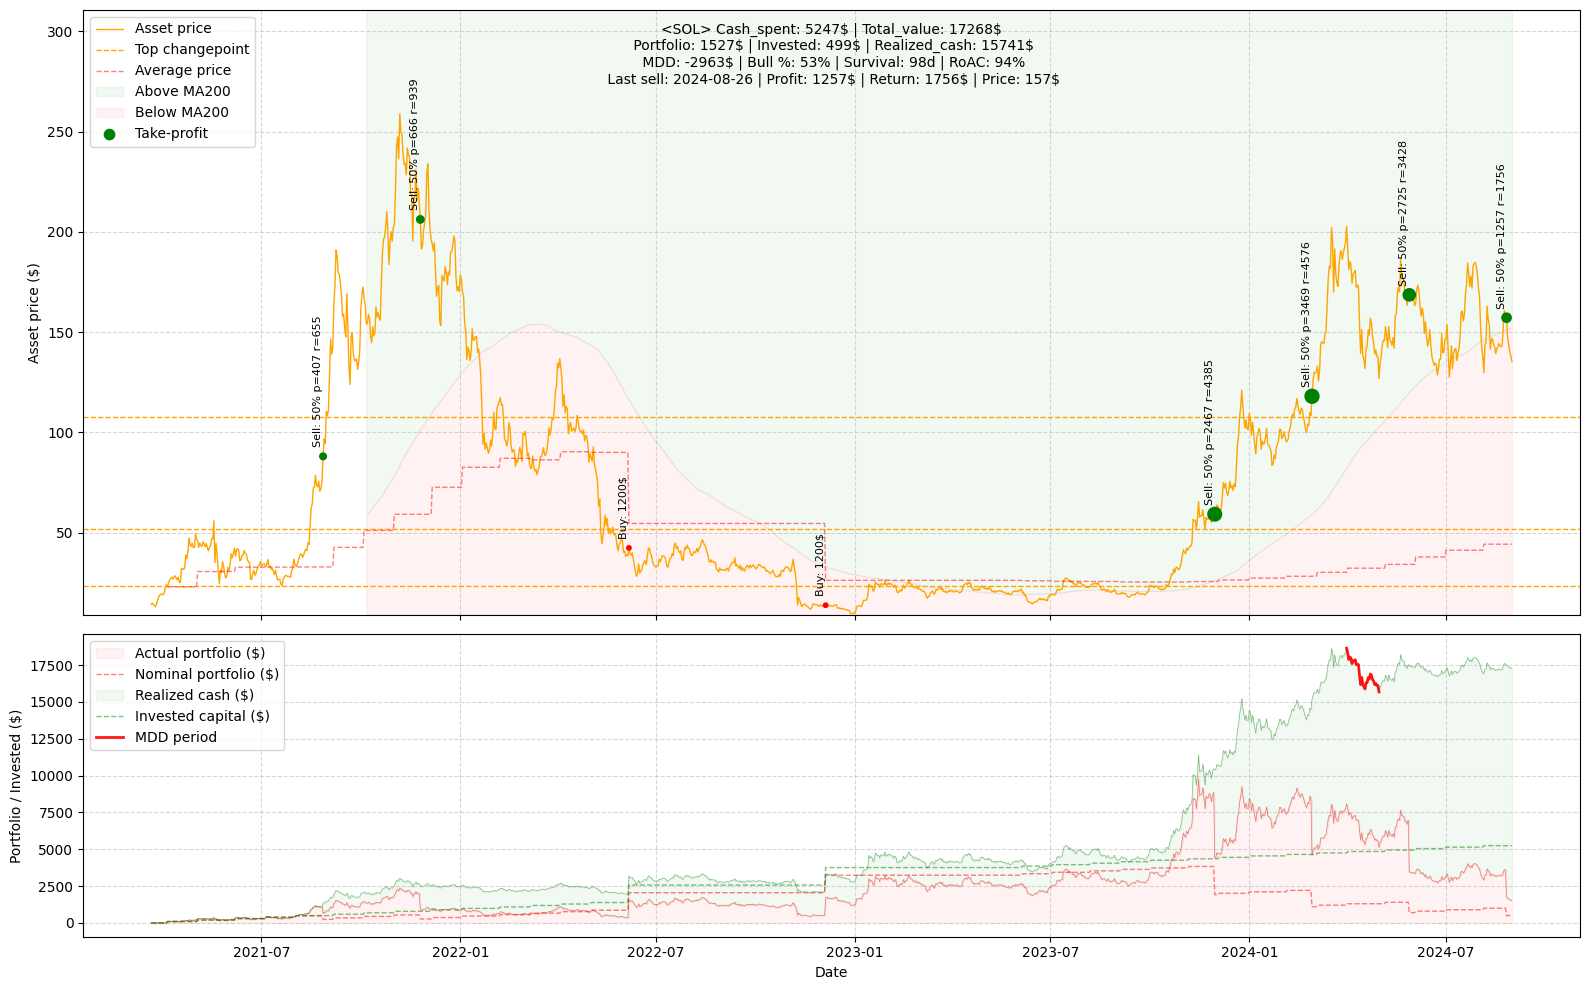

17:42:11 - cmdstanpy - INFO - Chain [1] start processing
17:42:11 - cmdstanpy - INFO - Chain [1] done processing


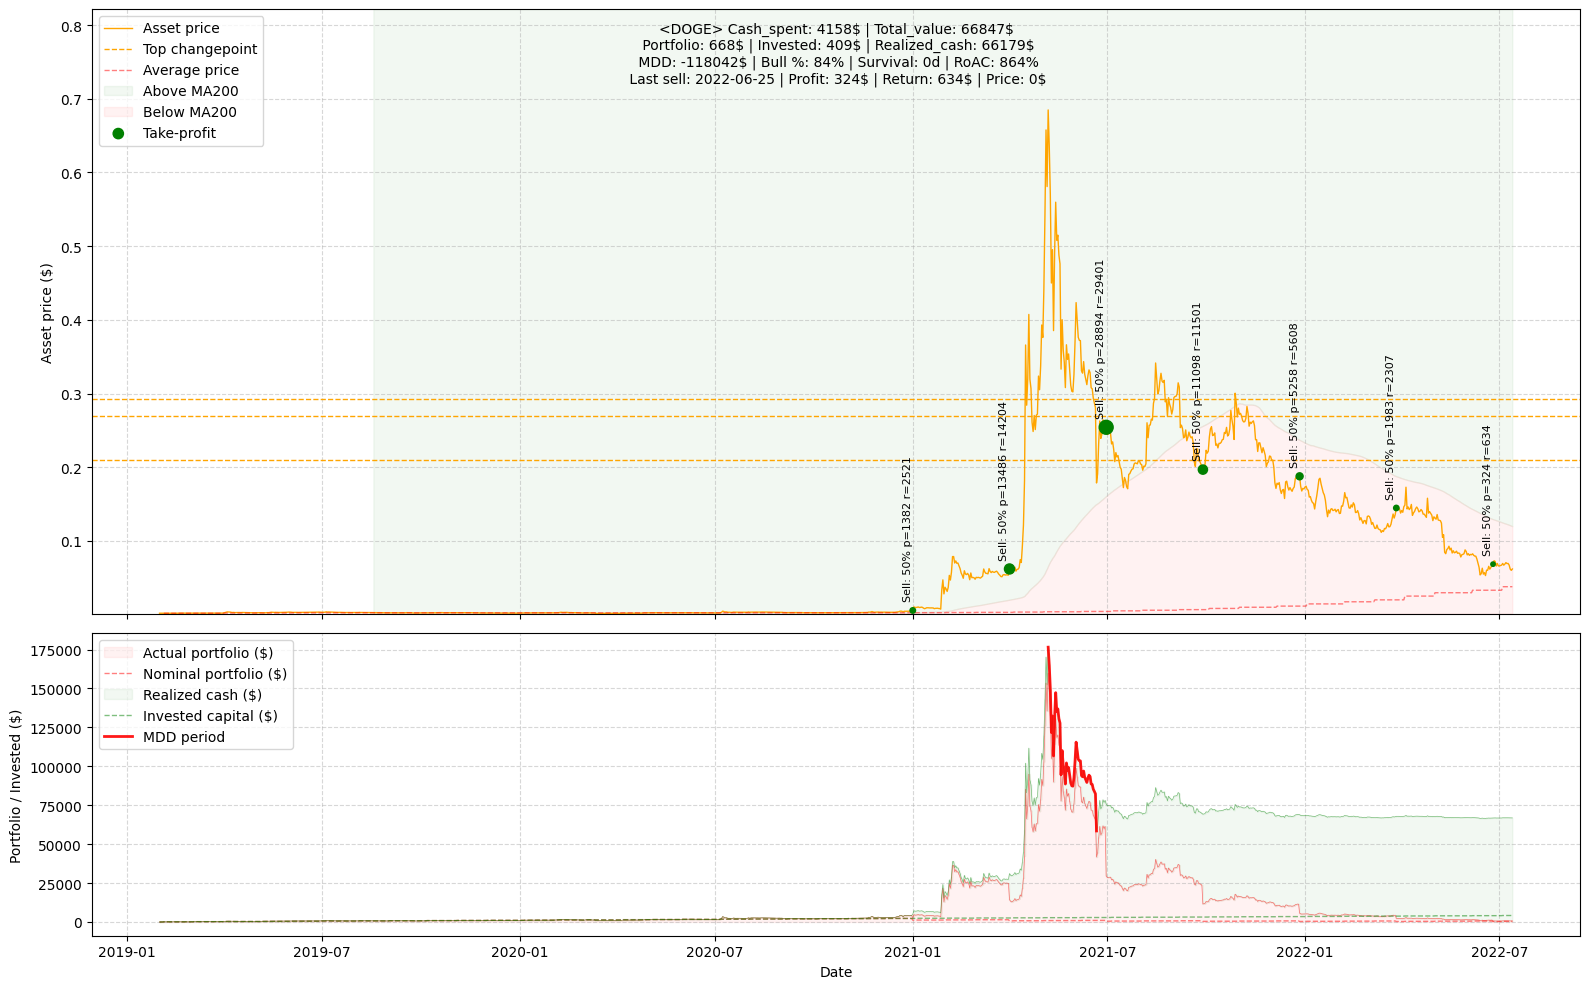

17:42:11 - cmdstanpy - INFO - Chain [1] start processing
17:42:12 - cmdstanpy - INFO - Chain [1] done processing


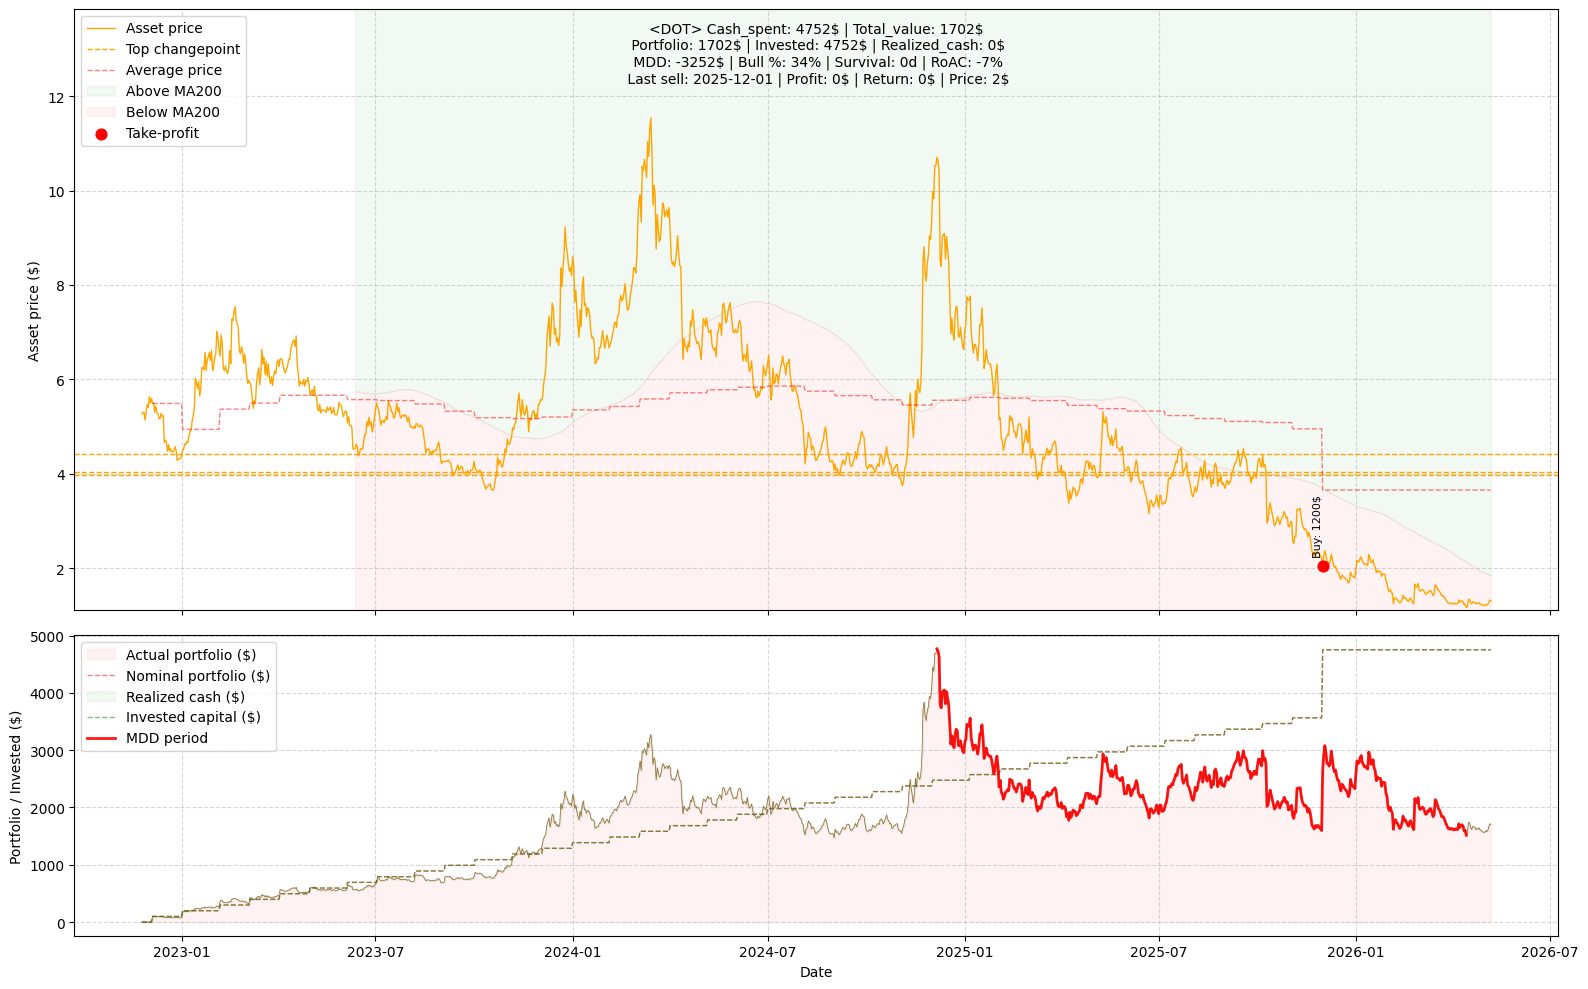

17:42:12 - cmdstanpy - INFO - Chain [1] start processing
17:42:12 - cmdstanpy - INFO - Chain [1] done processing


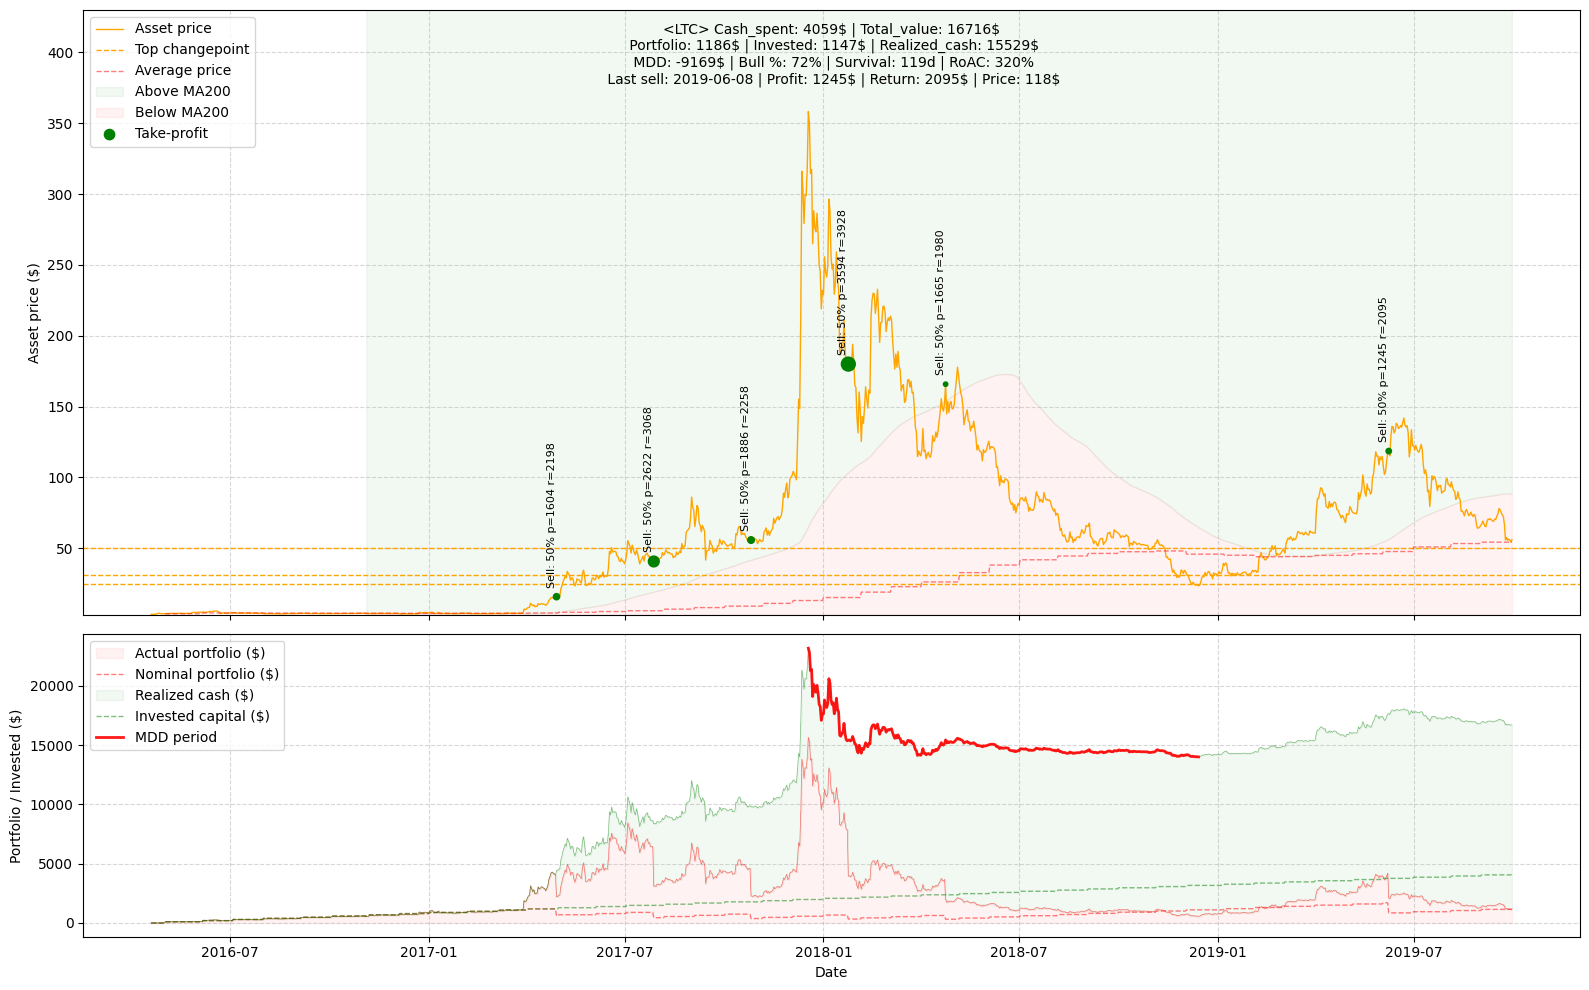

17:42:12 - cmdstanpy - INFO - Chain [1] start processing
17:42:13 - cmdstanpy - INFO - Chain [1] done processing


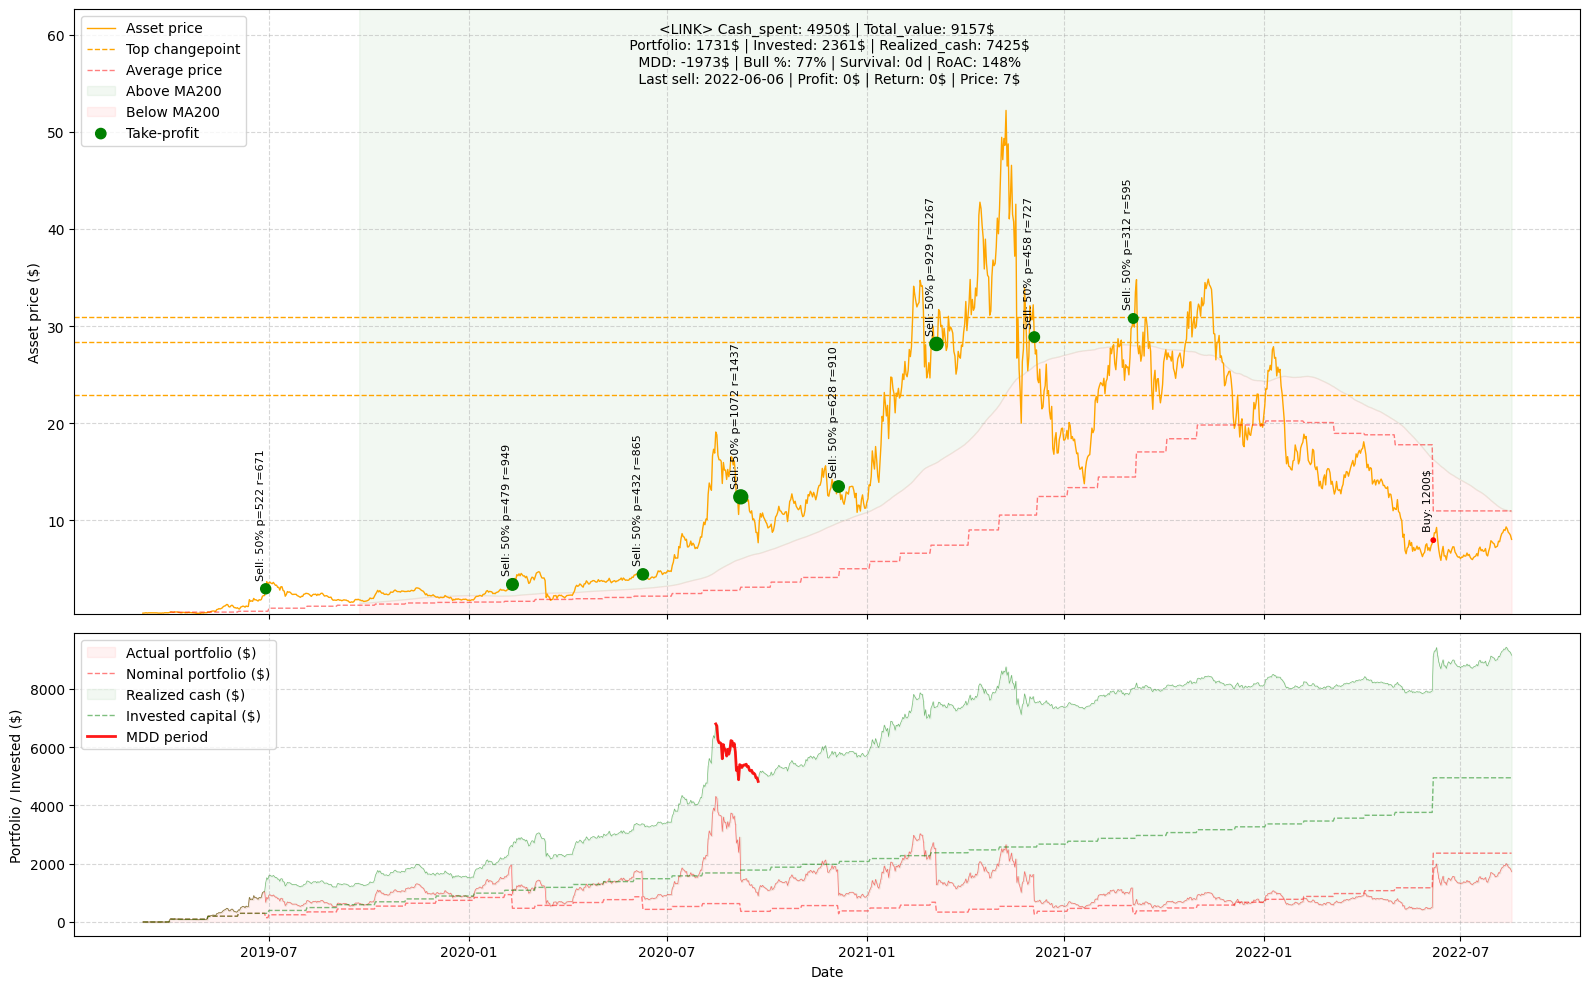

17:42:13 - cmdstanpy - INFO - Chain [1] start processing
17:42:13 - cmdstanpy - INFO - Chain [1] done processing


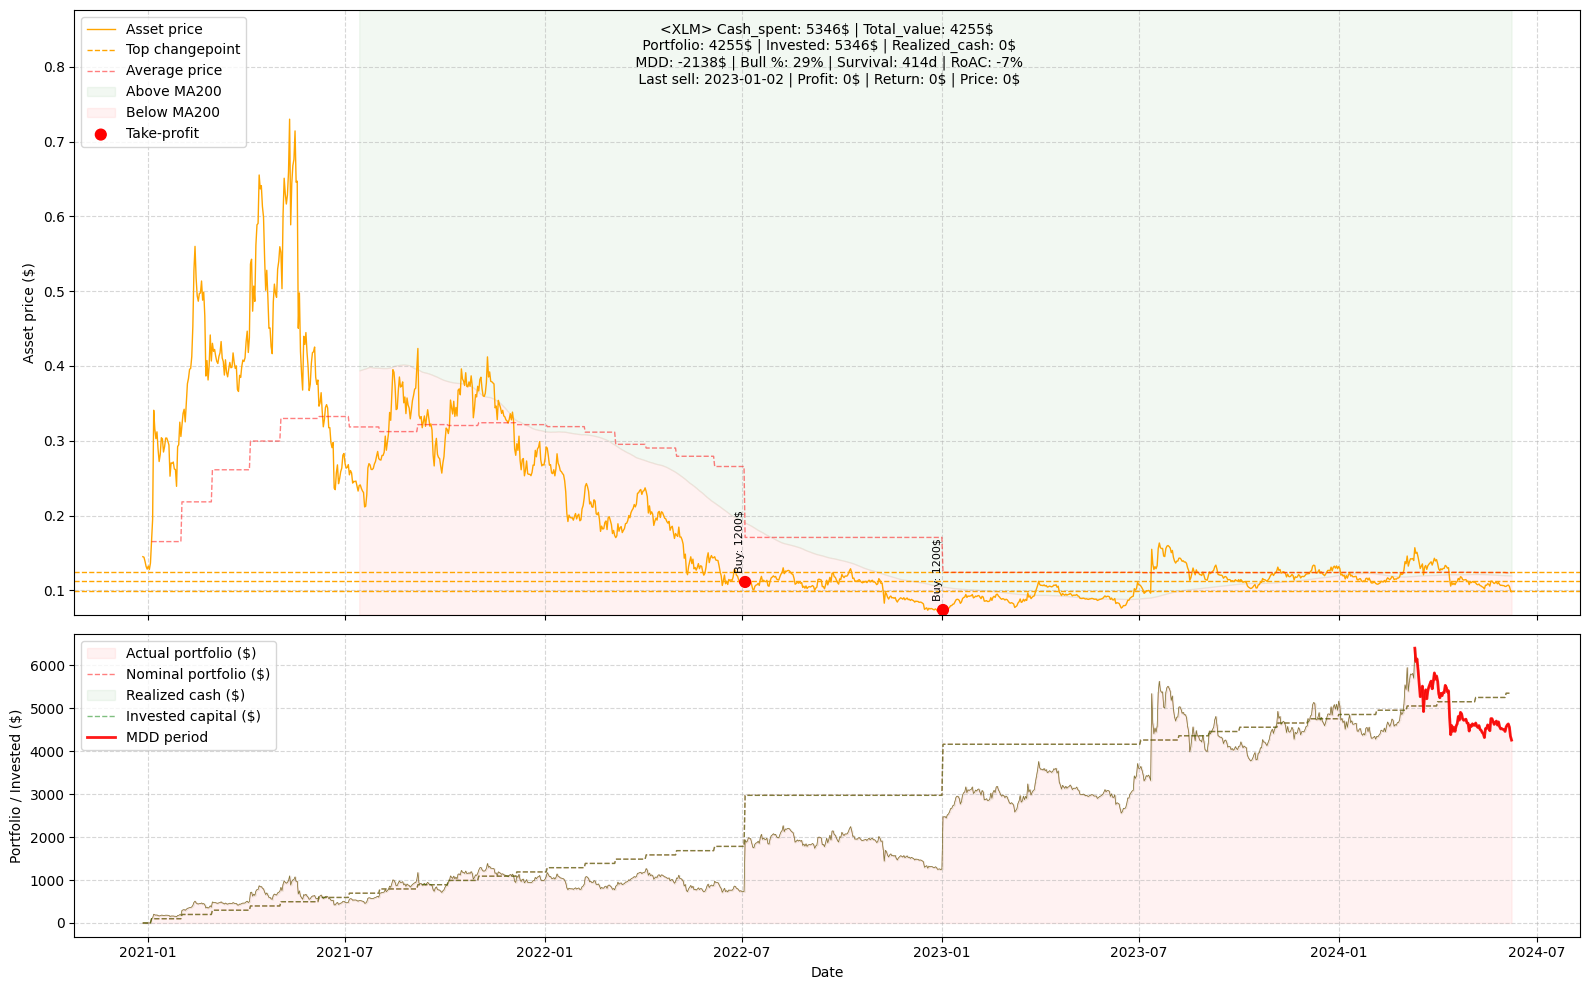

17:42:14 - cmdstanpy - INFO - Chain [1] start processing
17:42:14 - cmdstanpy - INFO - Chain [1] done processing


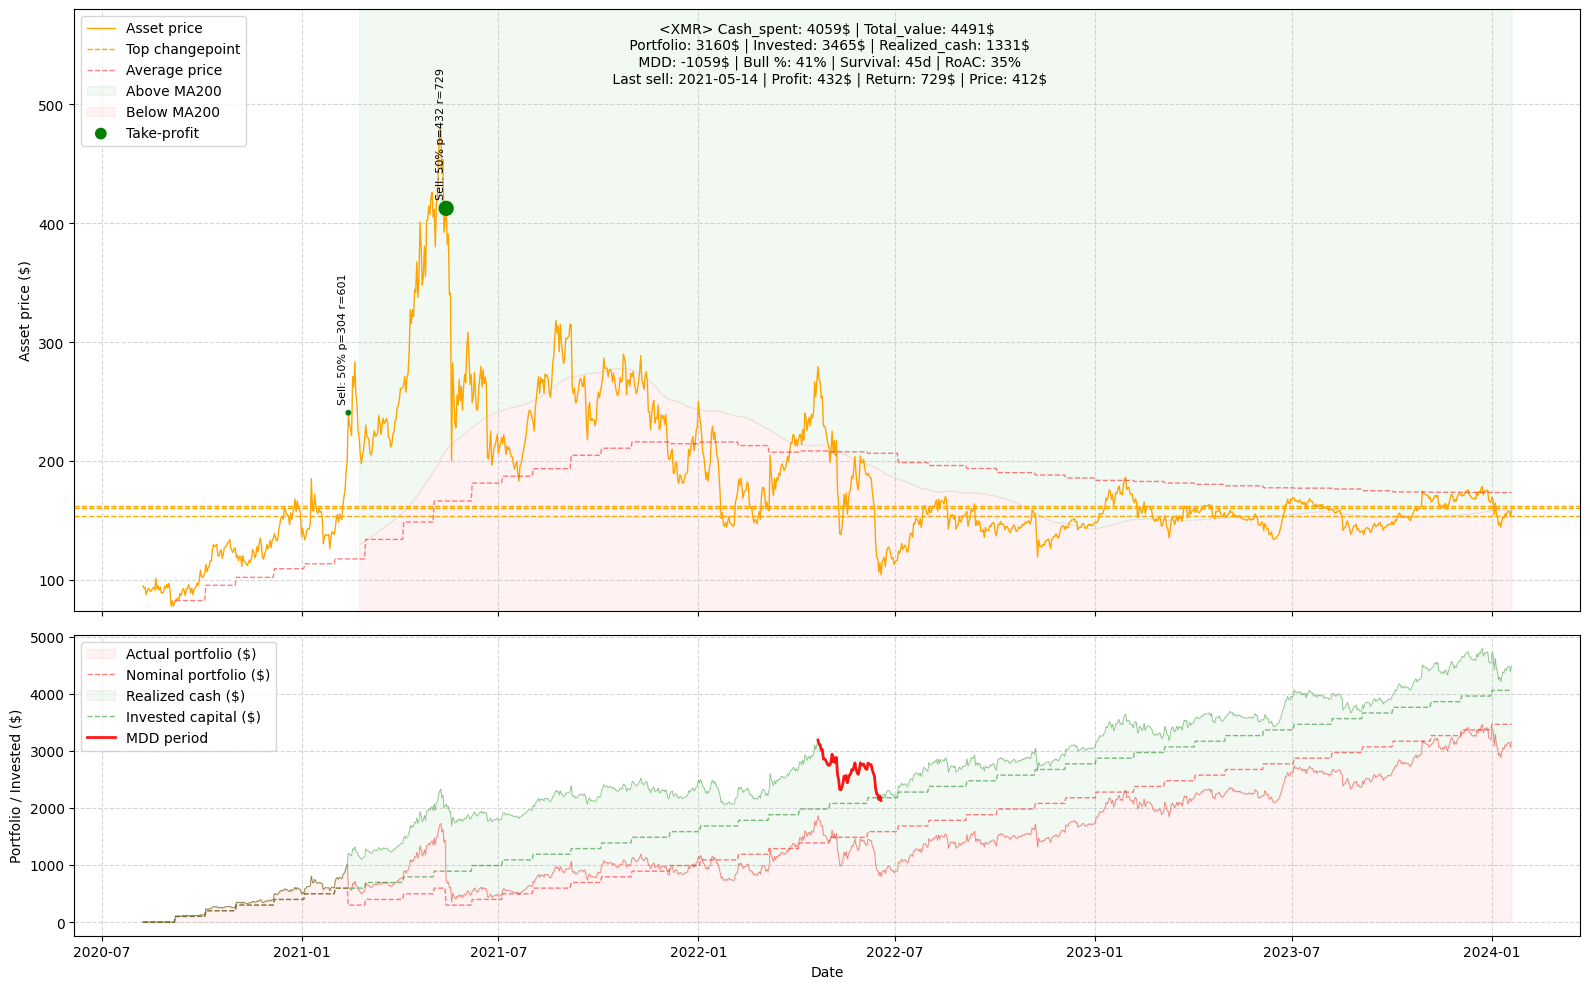

17:42:14 - cmdstanpy - INFO - Chain [1] start processing
17:42:14 - cmdstanpy - INFO - Chain [1] done processing


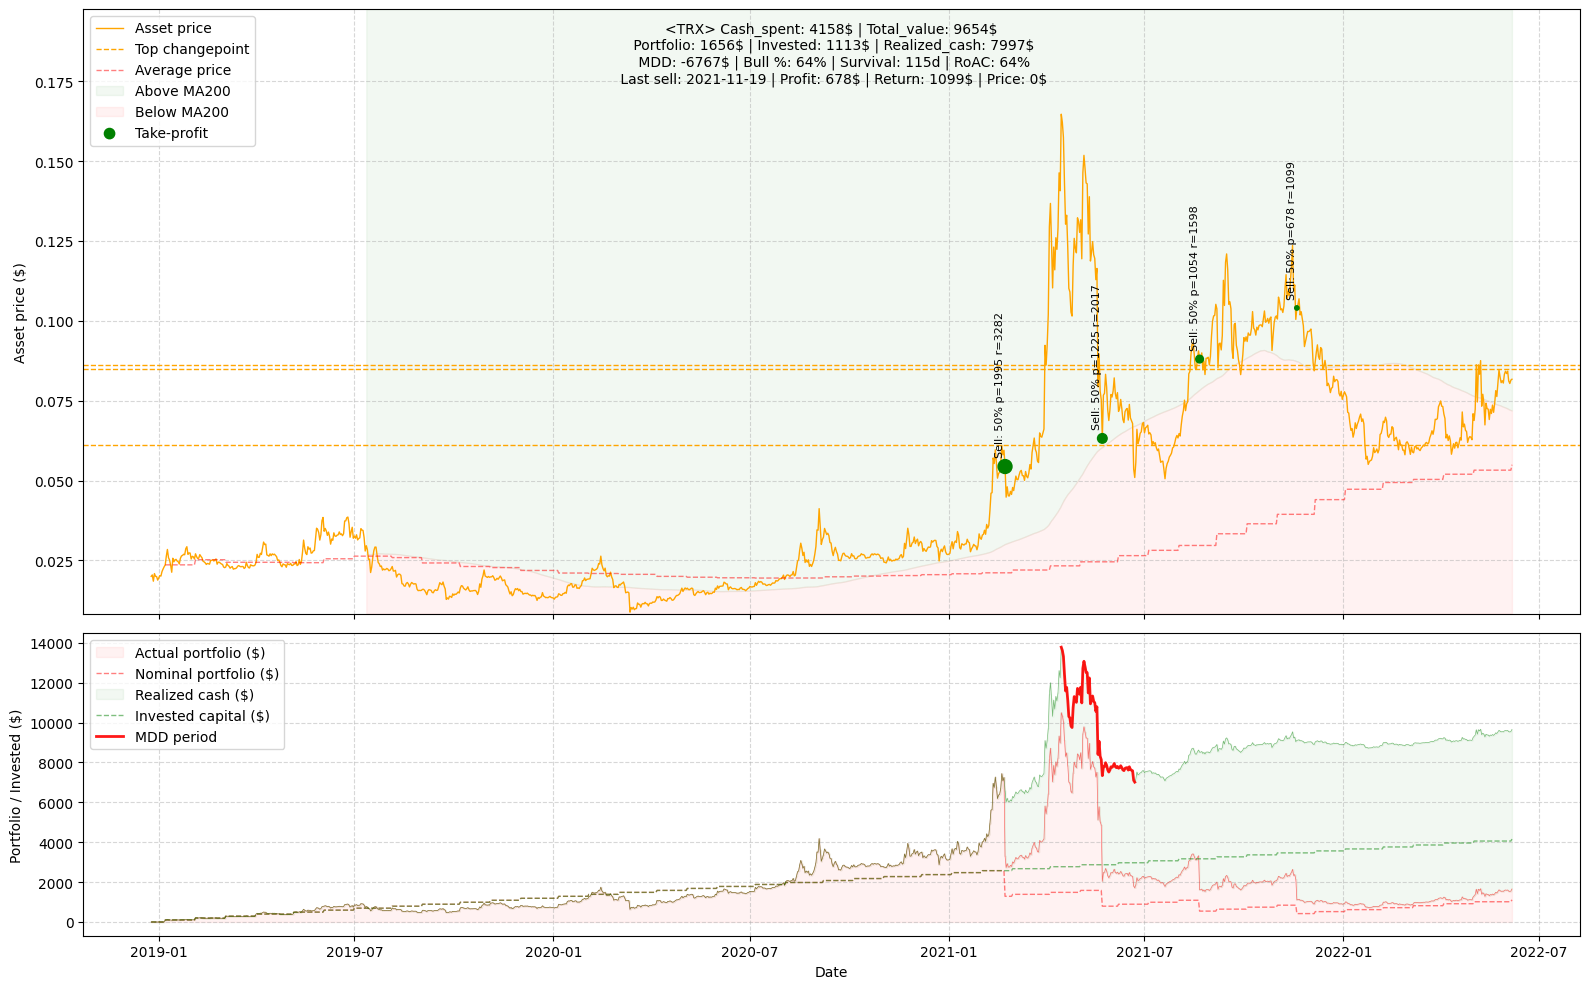

17:42:15 - cmdstanpy - INFO - Chain [1] start processing
17:42:15 - cmdstanpy - INFO - Chain [1] done processing


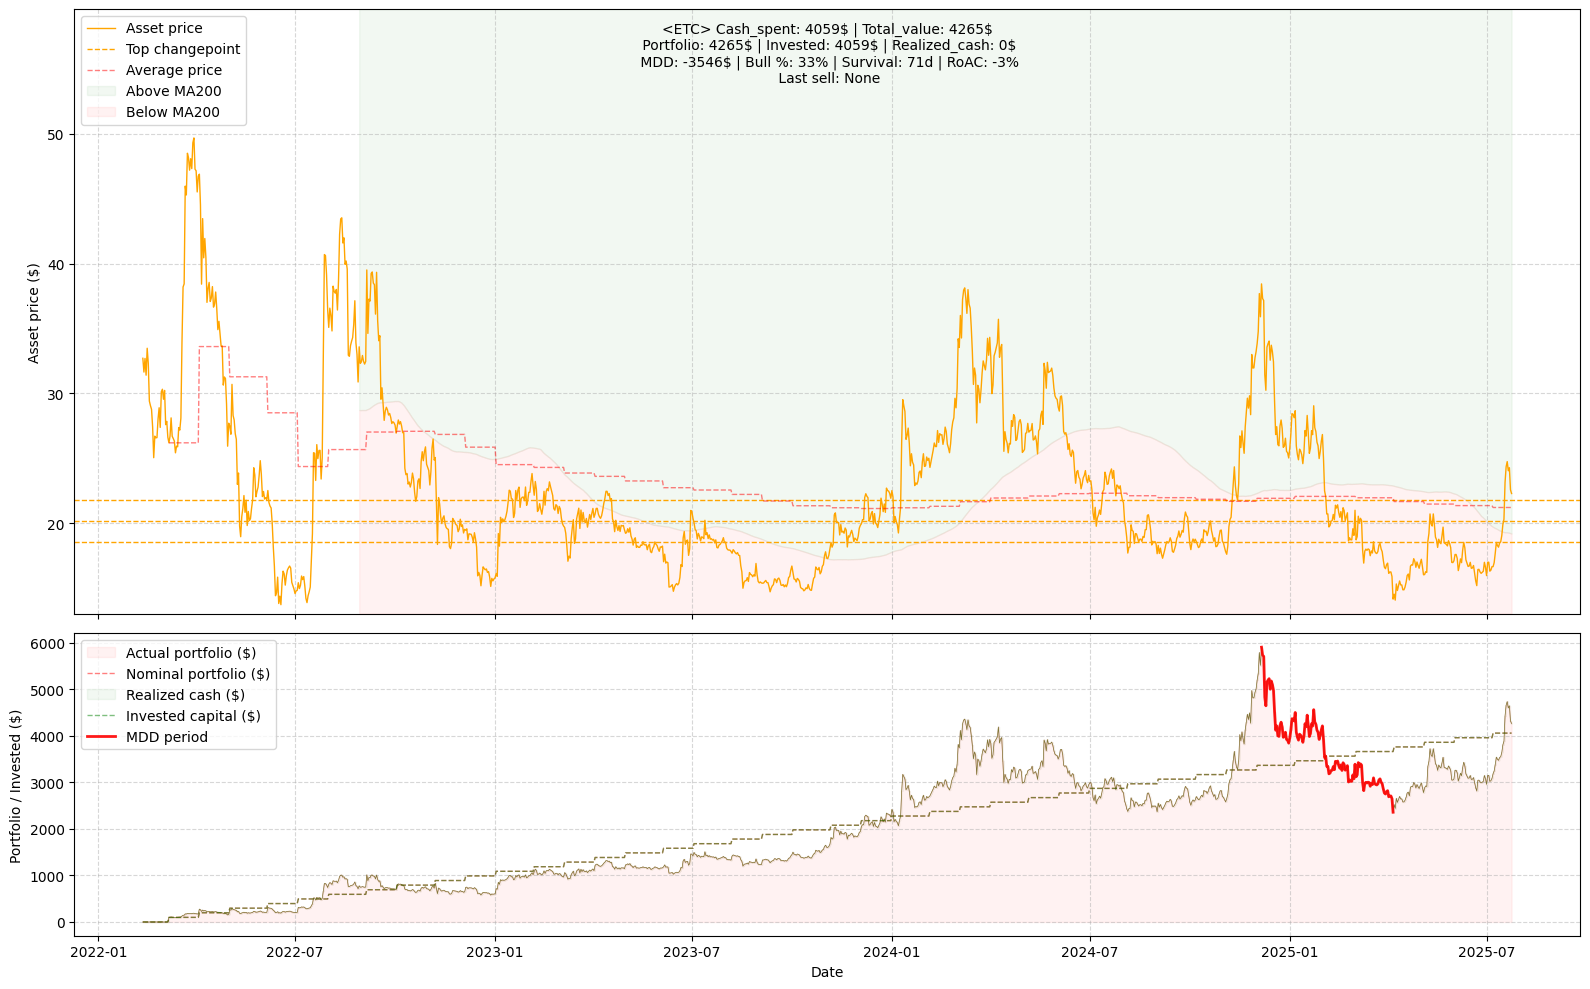

17:42:15 - cmdstanpy - INFO - Chain [1] start processing
17:42:15 - cmdstanpy - INFO - Chain [1] done processing


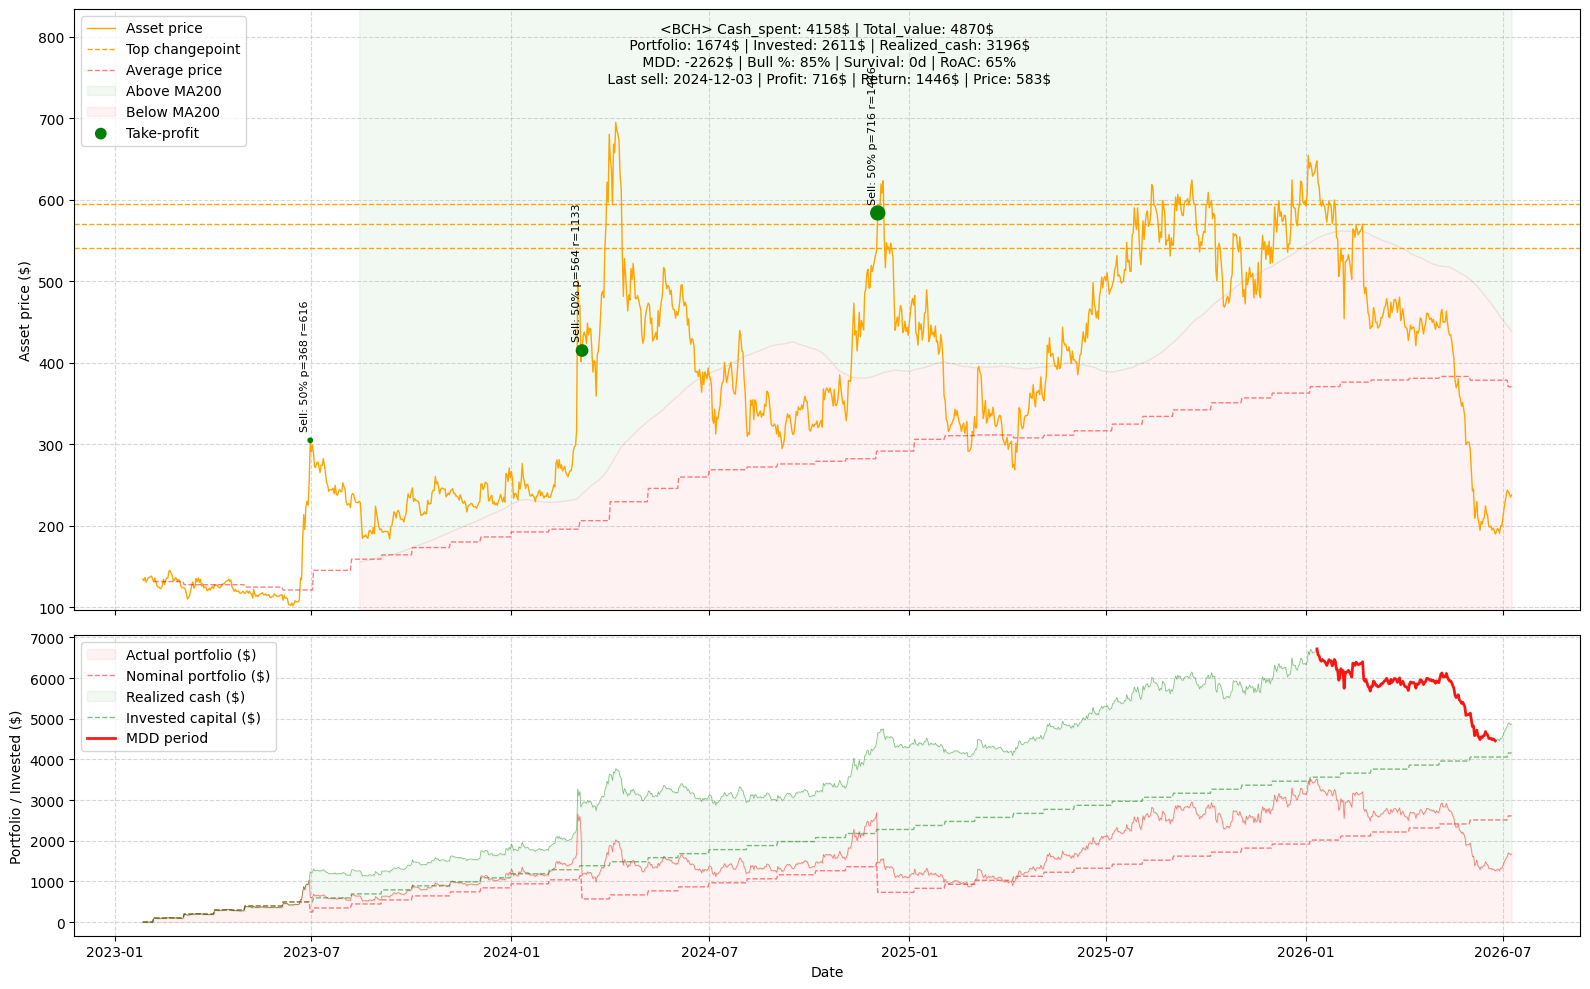

17:42:15 - cmdstanpy - INFO - Chain [1] start processing
17:42:16 - cmdstanpy - INFO - Chain [1] done processing


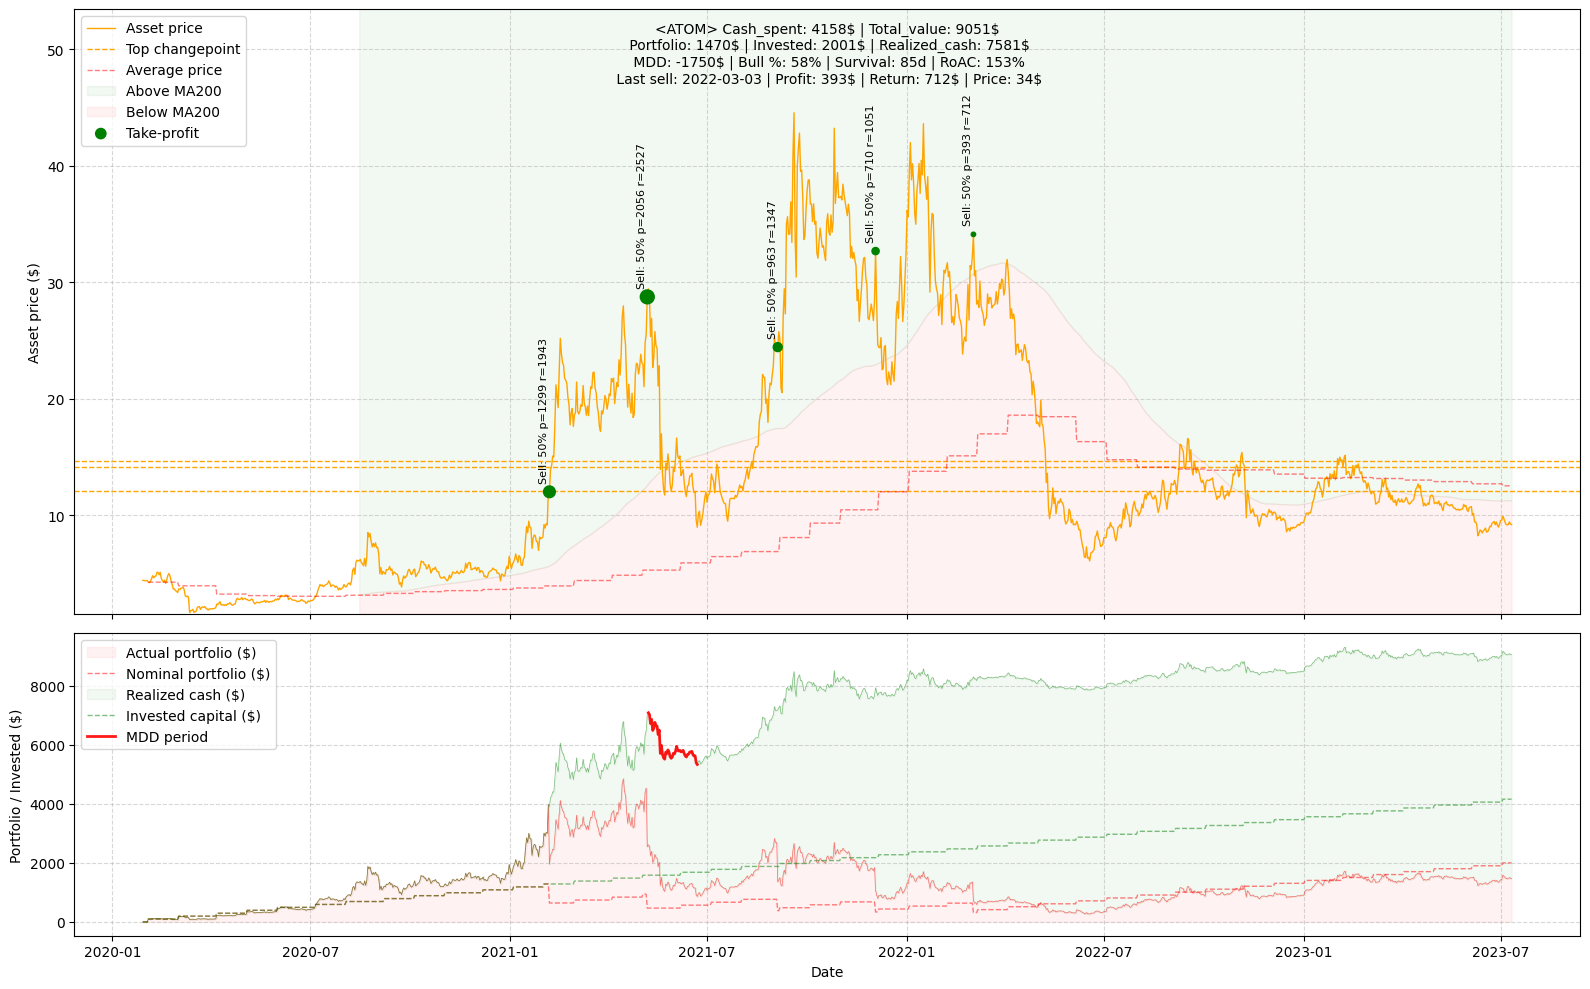

17:42:16 - cmdstanpy - INFO - Chain [1] start processing
17:42:16 - cmdstanpy - INFO - Chain [1] done processing


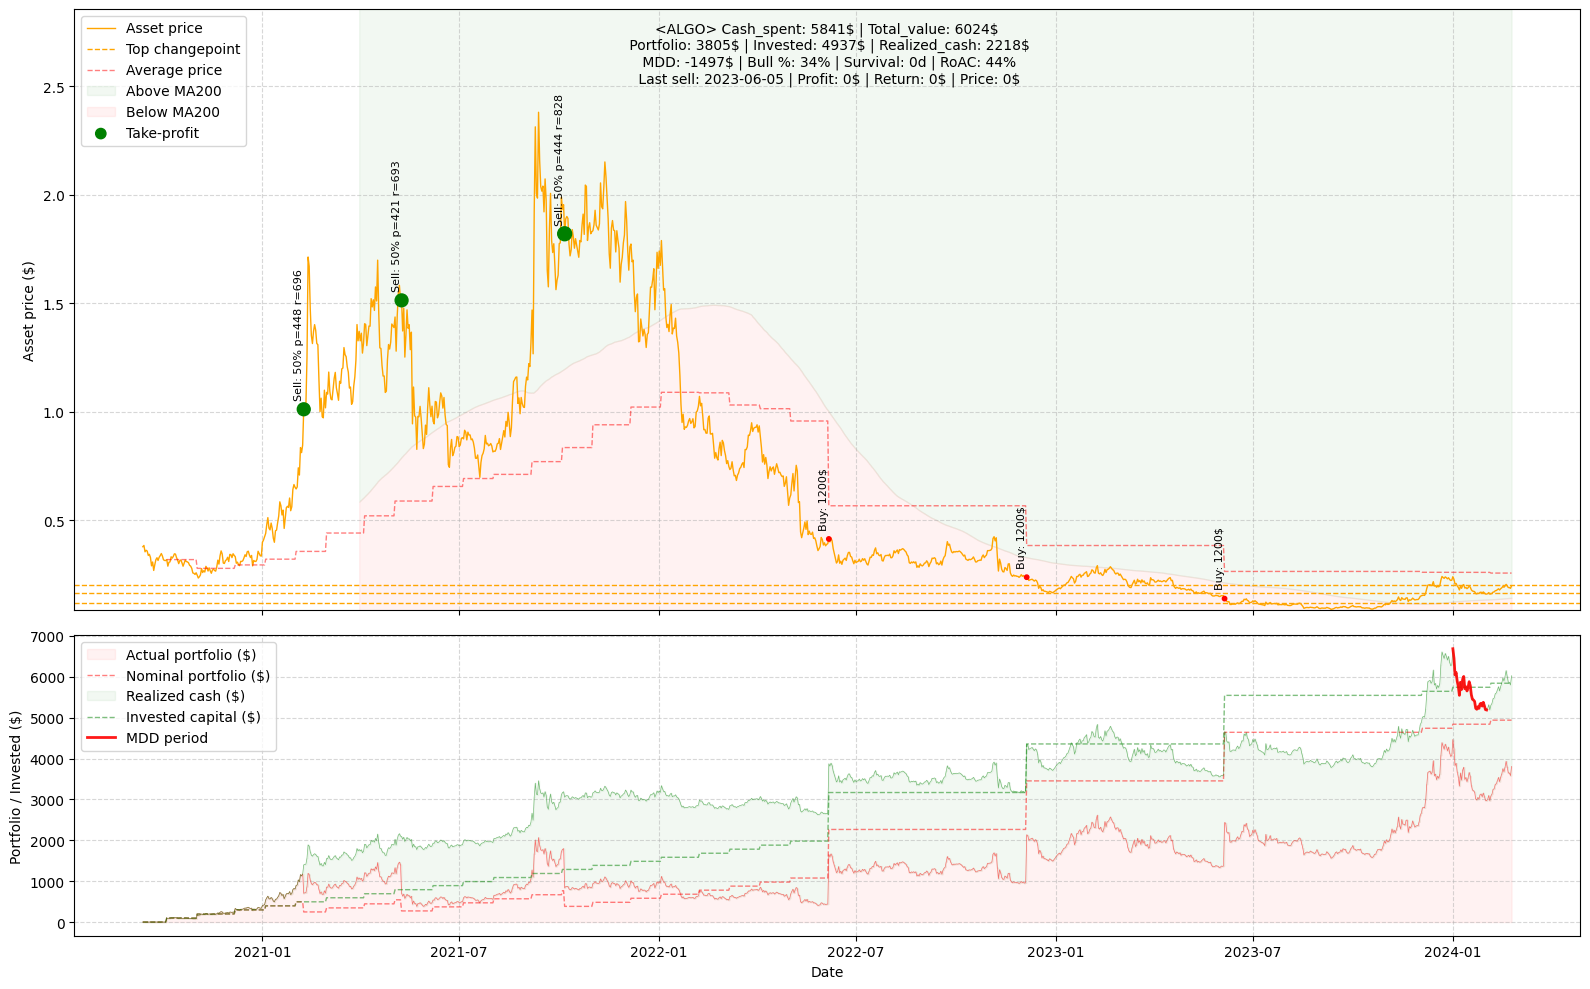

17:42:17 - cmdstanpy - INFO - Chain [1] start processing
17:42:17 - cmdstanpy - INFO - Chain [1] done processing


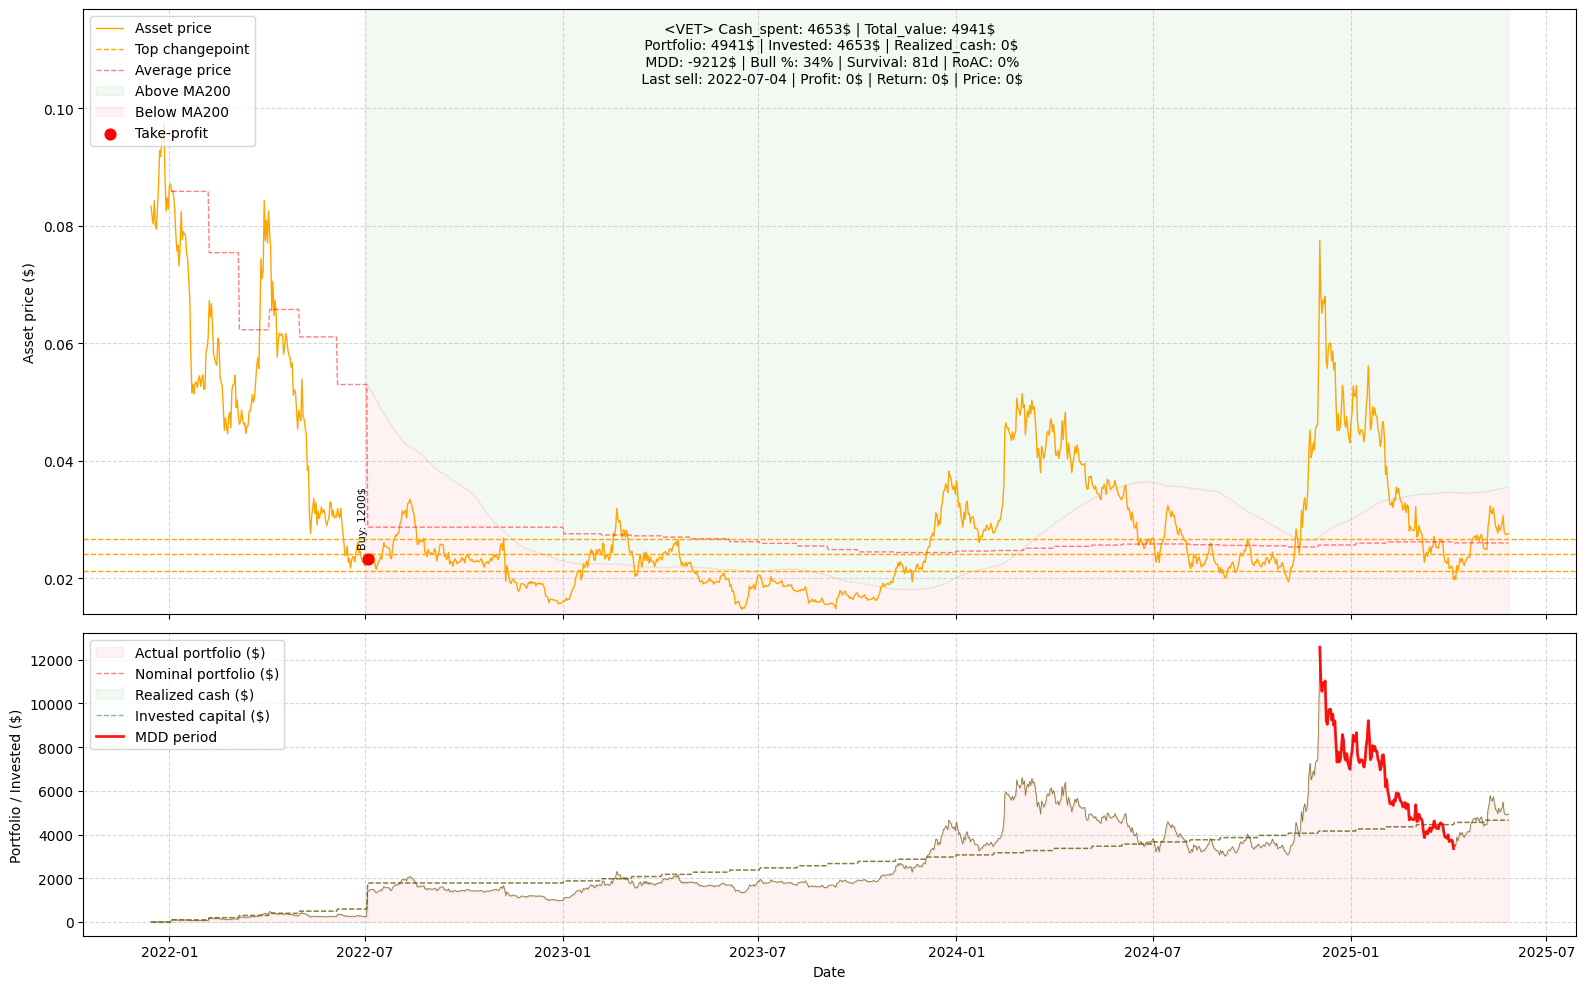

17:42:17 - cmdstanpy - INFO - Chain [1] start processing
17:42:17 - cmdstanpy - INFO - Chain [1] done processing


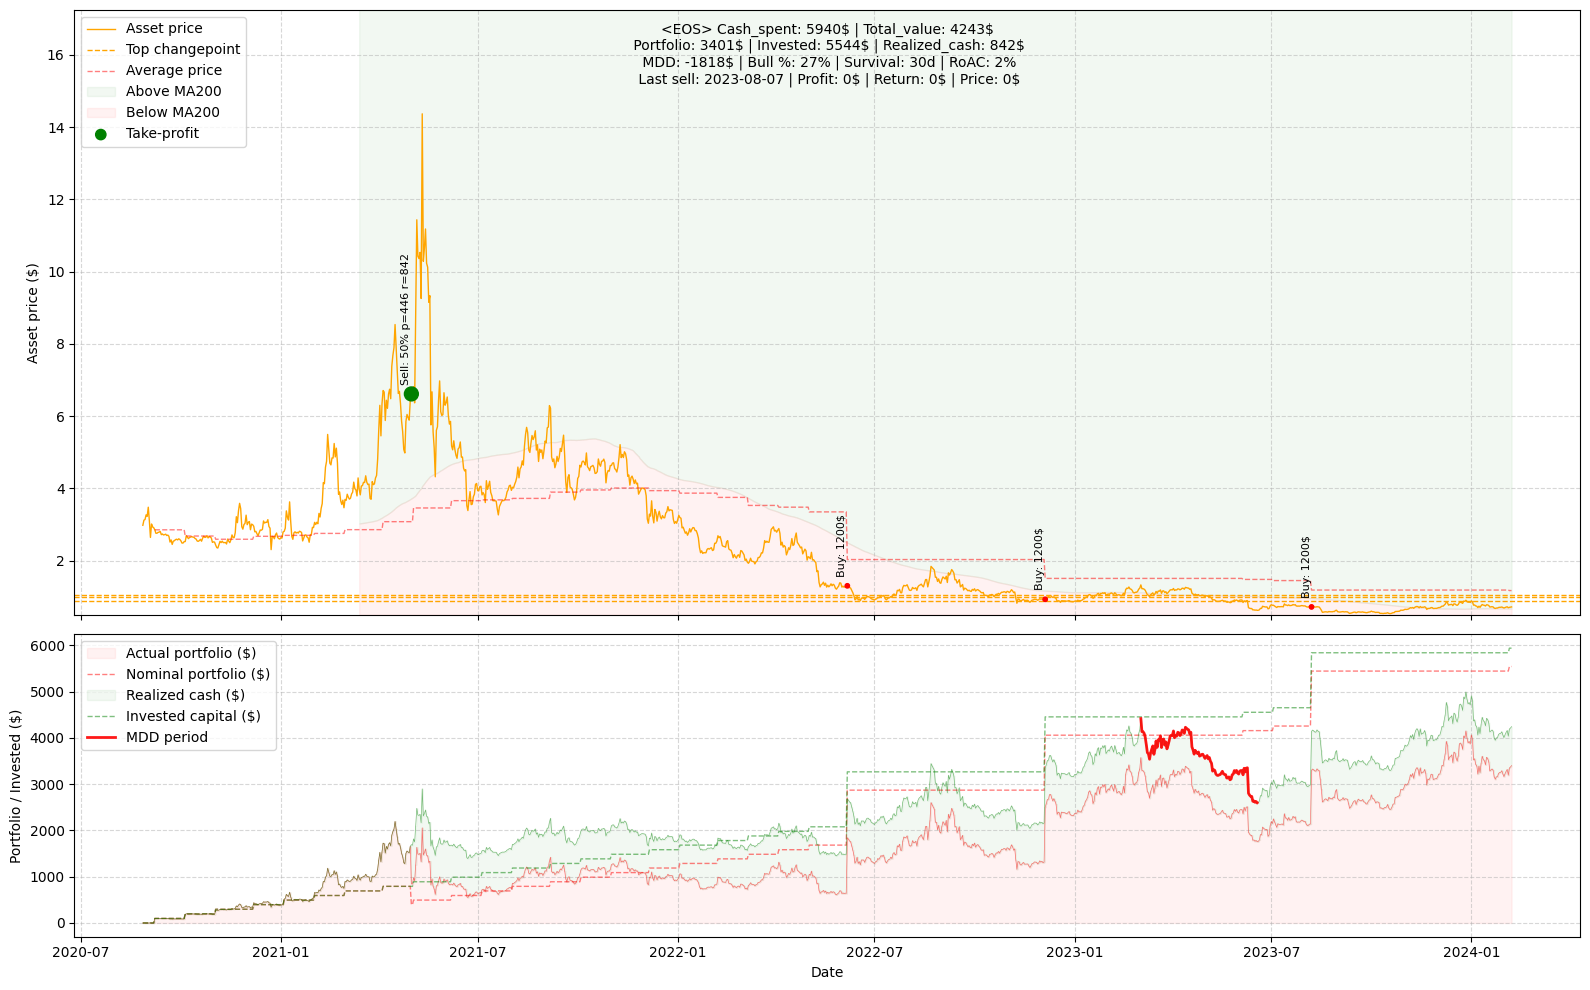

17:42:18 - cmdstanpy - INFO - Chain [1] start processing
17:42:18 - cmdstanpy - INFO - Chain [1] done processing


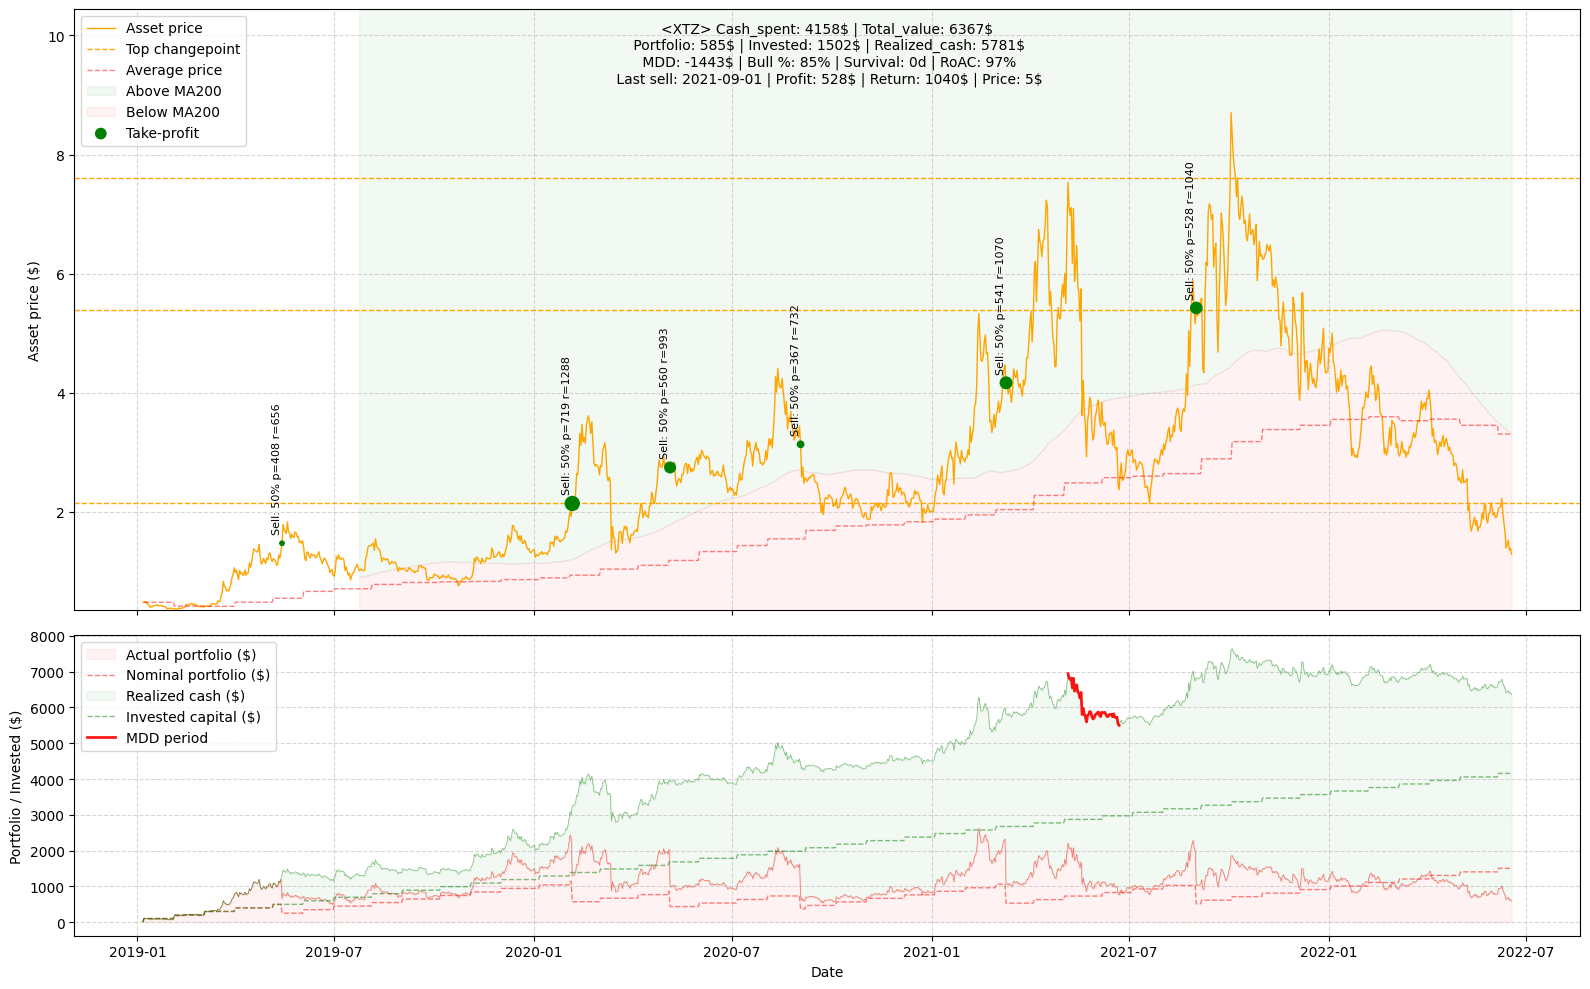

17:42:18 - cmdstanpy - INFO - Chain [1] start processing
17:42:18 - cmdstanpy - INFO - Chain [1] done processing


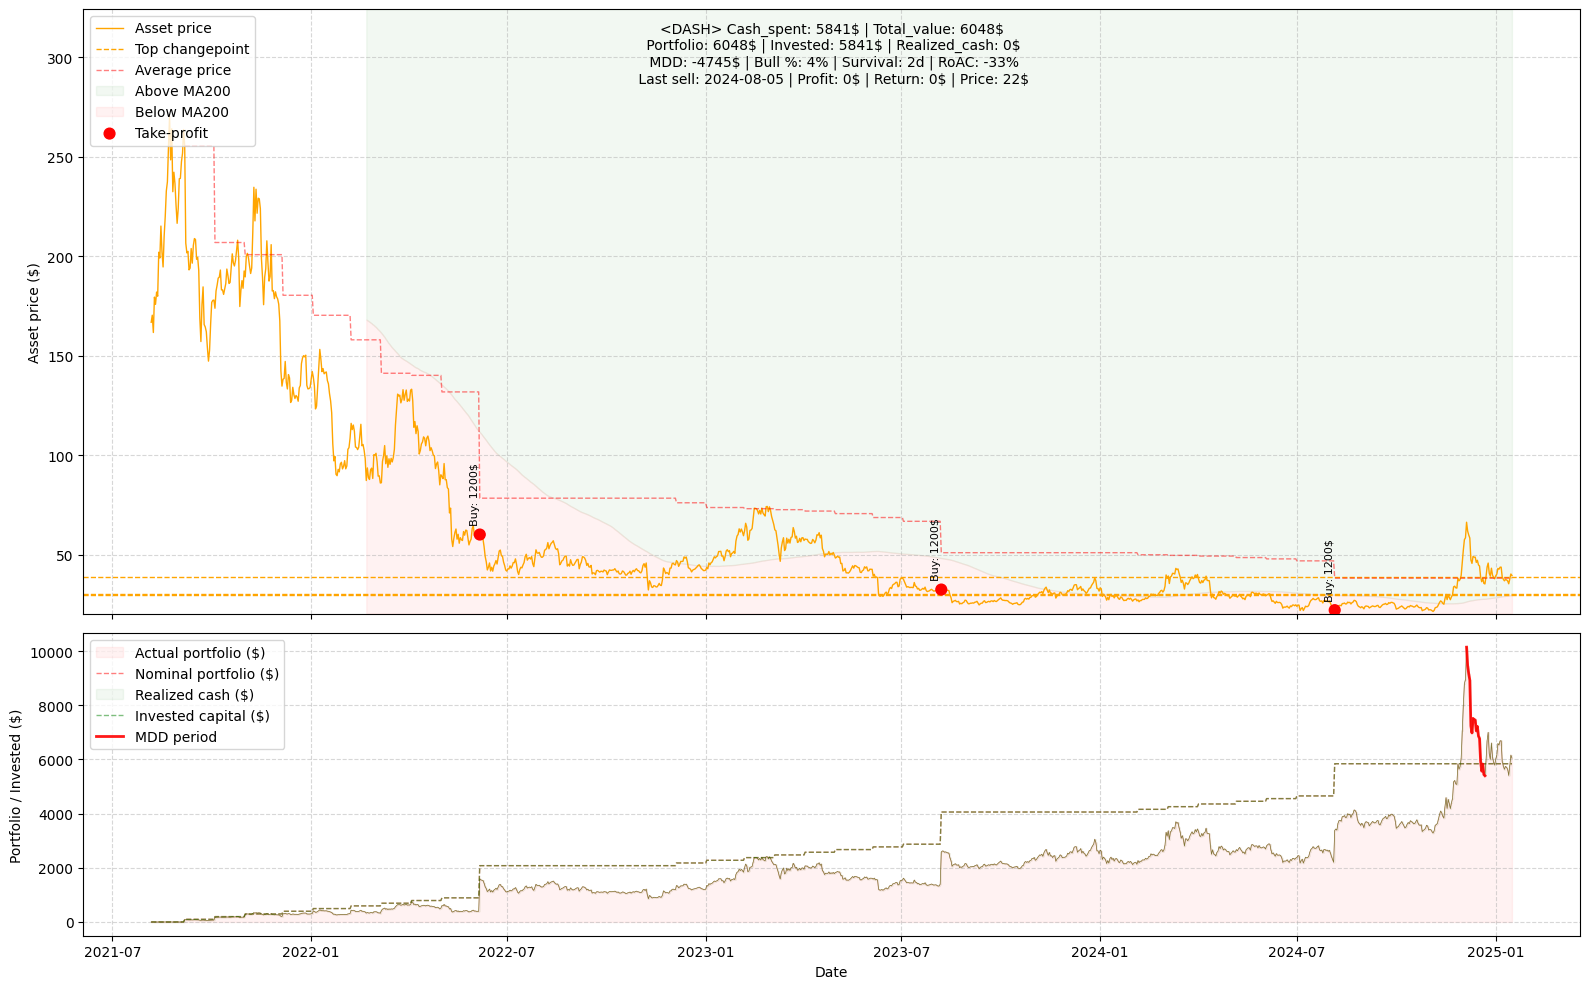

17:42:19 - cmdstanpy - INFO - Chain [1] start processing
17:42:19 - cmdstanpy - INFO - Chain [1] done processing


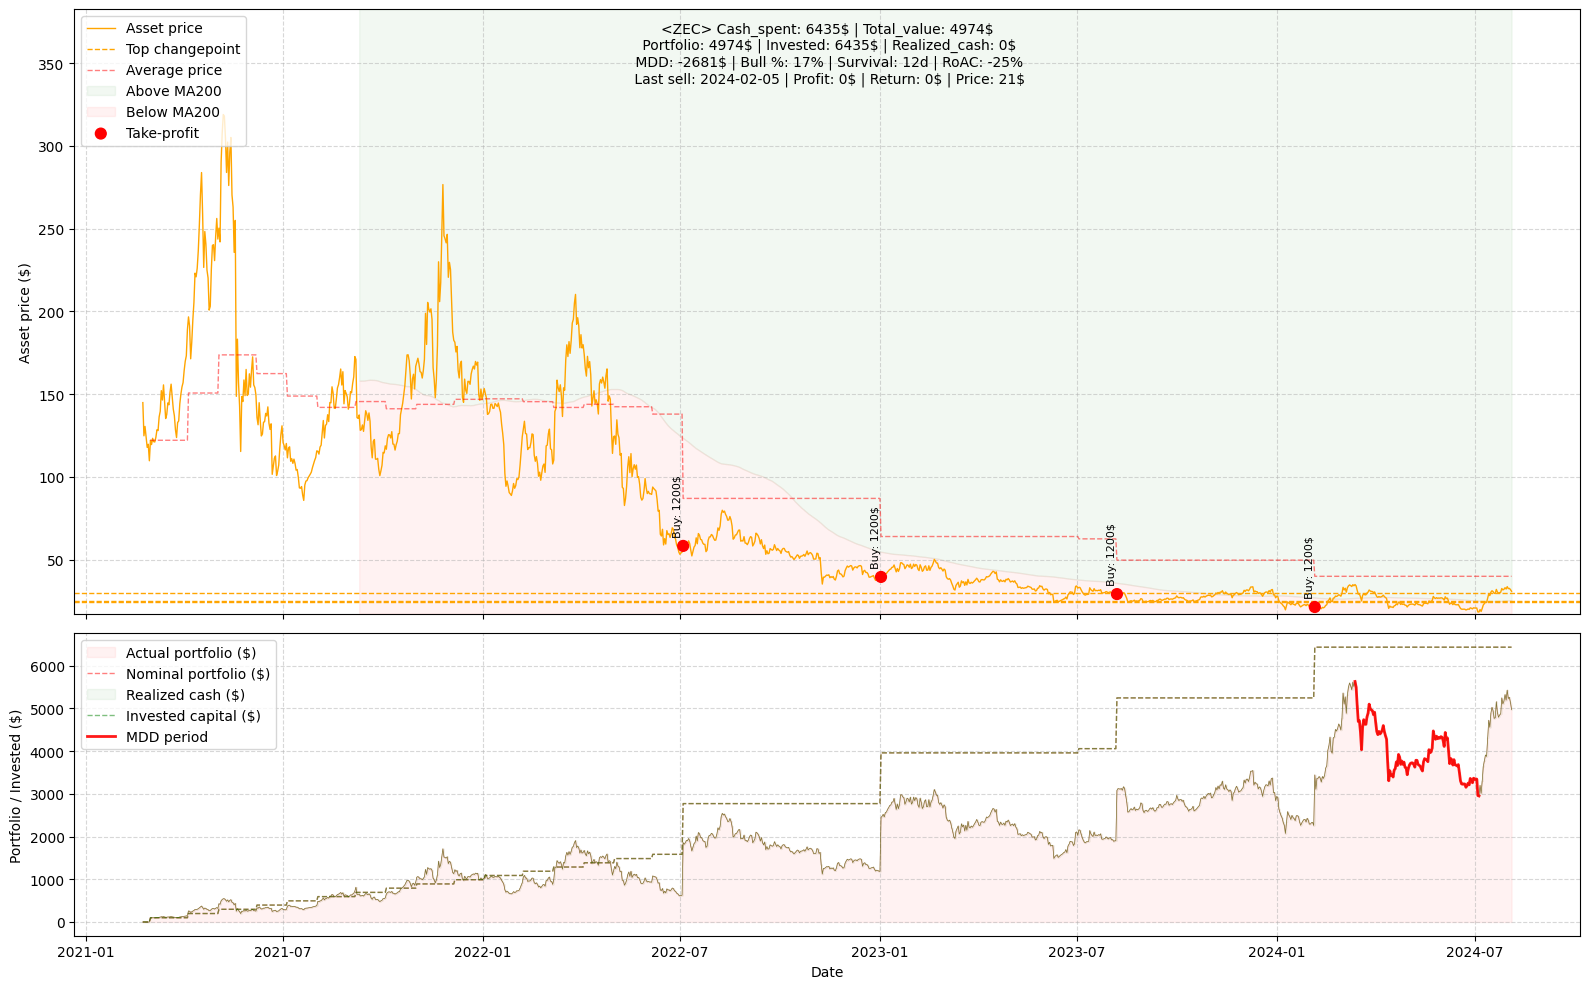

ValueError: empty range in randint(0, -1460)

In [6]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in df_stocks.columns:

    prices = df_stocks[stock]
    prices = prices.dropna()
    start = random.randint(0, len(prices) - SEQUENCE_LENGTH)
    prices = prices.iloc[start:start + SEQUENCE_LENGTH]
    prices = prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [ ]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2022-02-02,0.009757,0.000000,0.0000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-02-03,0.009839,0.000000,0.0000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-02-04,0.010847,0.000000,0.0000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-02-05,0.011240,0.000000,0.0000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2022-02-06,0.011501,0.000000,0.0000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
...,...,...,...,...,...,...,...,...,...,...,...
2025-07-11,0.006219,157590.618330,587.8125,2544.3,0.0,0.0,4350.773329,,980.056070,0.003730,5330.829398
2025-07-12,0.006153,157590.618330,587.8125,2544.3,0.0,0.0,4350.773329,,969.655083,0.003730,5320.428412
2025-07-13,0.006496,157590.618330,587.8125,2544.3,0.0,0.0,4350.773329,,1023.708673,0.003730,5374.482002


In [ ]:
(result['Portfolio'] > 0).sum()

np.int64(1255)

In [ ]:
metrics

{'Target': 'XVG',
 'Cash_spent': 2554,
 'Realized_cash': 4350,
 'Portfolio': 1065,
 'Invested': 597,
 'Total_value': 5416,
 'Bull_history': 62,
 'MDD': -3706,
 'Survival': 62.75000000000001,
 'RoAC': 48}